In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon
import math

# ==========================================
# 1. LOAD AND PREP DATA
# ==========================================
df = pd.read_csv('h3n2_clean/h3n2_clean_LV/5_Raw_Hamming_Distances.csv')

# Clean model names to group vaccines uniformly
def fix_model_names(name):
    name_str = str(name).lower()
    if '_vaccine' in name_str or 'vaccine' in name_str: return 'Vaccine Strain'
    if 'hotspot' in name_str: return 'Ensemble_all'
    if 'train' in name_str: return 'Train_consensus'
    if name_str.startswith('ensemble_en'): return 'Ensemble_Entropy'
    if name_str.startswith('ensemble_en'): return 'Ensemble_Entropy'
    if name_str.startswith('vaccine'): return 'Vaccine Strains'
    if name_str.startswith('representative'): return 'Test_consensus'
    if 'lstm' in name_str: return 'LSTM_prediction'
    if 'linear' in name_str: return 'Linear_prediction'
    return name

df['Model'] = df['Model'].apply(fix_model_names)
df = df[~df['Model'].str.startswith('Ensemble')]

ordered_models = df['Model'].drop_duplicates().tolist()
df['Model'] = pd.Categorical(df['Model'], categories=ordered_models, ordered=True)
df2 = df[~df['Model'].isin(['Transformer_4L', 'Transformer_5L','Train_consensus', 'Test_consensus'])].copy()

baseline_name = 'Vaccine Strain'

def get_asterisks(p_val):
    if pd.isna(p_val): return ""
    if p_val < 0.001: return "***"
    if p_val < 0.01: return "**"
    if p_val < 0.05: return "*"
    return "ns"

def get_model_rank(name):
    name_str = str(name)
    if name_str.startswith('Transformer'): return 1
    elif name_str.startswith('Ensemble'): return 2
    elif name_str.startswith('LSTM'): return 3
    elif name_str.startswith('Linear'): return 4
    else: return 5

df2['Sort_Rank'] = df2['Model'].apply(get_model_rank)
df2 = df2.sort_values(by=['Sort_Rank', 'Model']).drop(columns=['Sort_Rank']).reset_index(drop=True)


# ==========================================
# 2. PLOTTING FUNCTION FOR SMALL MULTIPLES
# ==========================================
def plot_seasonal_small_multiples(df, metric, p_values_output_list):
    print(f"Generating Small Multiples for {metric}...")

    title_map = {
        'AllPos_Hamming': 'Complete HA Sequence',
        'Epitope_Hamming': 'Canonical Epitope Positions',
        'Shift_Hamming': 'Seasonally Shifted Positions'
    }
    position_label = title_map.get(metric, metric)
    
    seasons = sorted(df['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 3
    rows = math.ceil(num_seasons / cols)

    unique_sorted_models = df['Model'].unique()
    
    # Force baseline to the front, then keep the rest in your custom Sort_Rank order
    order = [baseline_name] + [m for m in unique_sorted_models if m != baseline_name]
    models = [m for m in order if m != baseline_name]
    
    base_colors = sns.color_palette("husl", len(models))
    model_colors = {baseline_name: '#85c1e9'} # Light blue for Baseline
    for idx, m in enumerate(models):
        model_colors[m] = base_colors[idx]
        
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows), sharex=True, sharey=True)
    axes = axes.flatten()
    
    global_y_max = df[metric].quantile(0.98)
    
    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df[df['Season'] == season]
        
        sns.boxplot(data=df_season, x='Model', y=metric, order=order, 
                    hue='Model', hue_order=order, dodge=False, legend=False,
                    ax=ax, palette=model_colors, showfliers=False)
        df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean')
        
        if baseline_name in df_pivot.columns:
            baseline_scores = df_pivot[baseline_name]
            b_med_overall = baseline_scores.median()
            
            for j, model in enumerate(order):
                if model == baseline_name:
                    ax.text(j, global_y_max, 'Vaccine', ha='center', va='bottom', fontsize=10, weight='bold', color='tab:blue')
                    continue
                    
                if model in df_pivot.columns:
                    model_scores = df_pivot[model]
                    
                    valid_mask = ~baseline_scores.isna() & ~model_scores.isna()
                    b_valid = baseline_scores[valid_mask]
                    m_valid = model_scores[valid_mask]
                    
                    if len(b_valid) > 0 and not b_valid.equals(m_valid):
                        stat, p = wilcoxon(b_valid, m_valid, zero_method='wilcox')
                        p_adj = min(p * len(models), 1.0)
                        stars = get_asterisks(p_adj)
                        
                        diff = m_valid - b_valid
                        
                        if stars != 'ns':
                            if diff.mean() < 0: 
                                color = 'tab:green'
                                outcome = 'Win'
                            elif diff.mean() > 0:
                                color = 'tab:red'
                                outcome = 'Loss'
                            else:
                                color = 'grey'
                                outcome = 'Tie'
                        else:
                            color = 'grey'
                            outcome = 'Tie'
                        
                        # 1. Plot the text (aligned with the main if statements)
                        ax.text(j, global_y_max, stars, ha='center', va='bottom', fontsize=14, weight='bold', color=color)
                        
                        # 2. Append the record (MUST be at the exact same indentation as ax.text)
                        p_values_output_list.append({
                            'Metric': metric,
                            'Season': season,
                            'Model': model,
                            'Baseline_Median': b_valid.median(),
                            'Model_Median': m_valid.median(),
                            'P_Value_Raw': p,
                            'P_Value_Bonferroni': p_adj,
                            'Significance_Stars': stars,
                            'Outcome (vs Baseline)': outcome
                        })
                        
                    elif len(b_valid) > 0 and b_valid.equals(m_valid):
                        stars = 'ns'
                        color = 'grey'
                        outcome = 'Tie (Identical)'
                        
                        ax.text(j, global_y_max, stars, ha='center', va='bottom', fontsize=14, weight='bold', color=color)
                        
                        p_values_output_list.append({
                            'Metric': metric,
                            'Season': season,
                            'Model': model,
                            'Baseline_Median': b_valid.median(),
                            'Model_Median': m_valid.median(),
                            'P_Value_Raw': 1.0,
                            'P_Value_Bonferroni': 1.0,
                            'Significance_Stars': 'ns',
                            'Outcome (vs Baseline)': outcome
                        })
                        
                        
        else:
            ax.text(0.5, 0.9, 'No Baseline Available', ha='center', va='center', 
                    transform=ax.transAxes, fontsize=12, color='tab:red', alpha=0.5)

        ax.set_title(f"Target year {season}", fontsize=13, weight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('Hamming Distance' if i % cols == 0 else '') # Cleaned up y-axis label too
        ax.yaxis.grid(True, linestyle='--', alpha=0.6)
        
        ax.tick_params(axis='x', rotation=45, labelsize=11)

    for k in range(i + 1, len(axes)):
        fig.delaxes(axes[k])
        
    # --- UPDATED MAIN TITLE ---
    plt.suptitle(f'Statistical Significance vs Vaccine Strain: {position_label}', 
                 fontsize=18, weight='bold', y=1.02)
    plt.tight_layout()
    
    filename = f"SmallMultiples_Stats_{metric}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()



In [2]:
df2.head()

,Season,Model,Test_Seq_ID,AllPos_Hamming,Shift_Hamming,Epitope_Hamming
0,2014,Transformer_3L,EPI_ISL_197519|A_H3N2|3C.2a|2015-01-26|Russian...,8,7,5
1,2014,Transformer_3L,EPI_ISL_197579|A_H3N2|3C.3a|2015-01-16|Russian...,8,5,5
2,2014,Transformer_3L,EPI_ISL_197578|A_H3N2|3C.2a|2014-12-17|Russian...,13,8,6
3,2014,Transformer_3L,EPI_ISL_197583|A_H3N2|3C.2a|2015-01-26|Russian...,8,7,5
4,2014,Transformer_3L,EPI_ISL_197582|A_H3N2|3C.2|2015-01-20|Russian_...,8,7,4


Generating Small Multiples for AllPos_Hamming...


/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean')
/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean')
/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_S

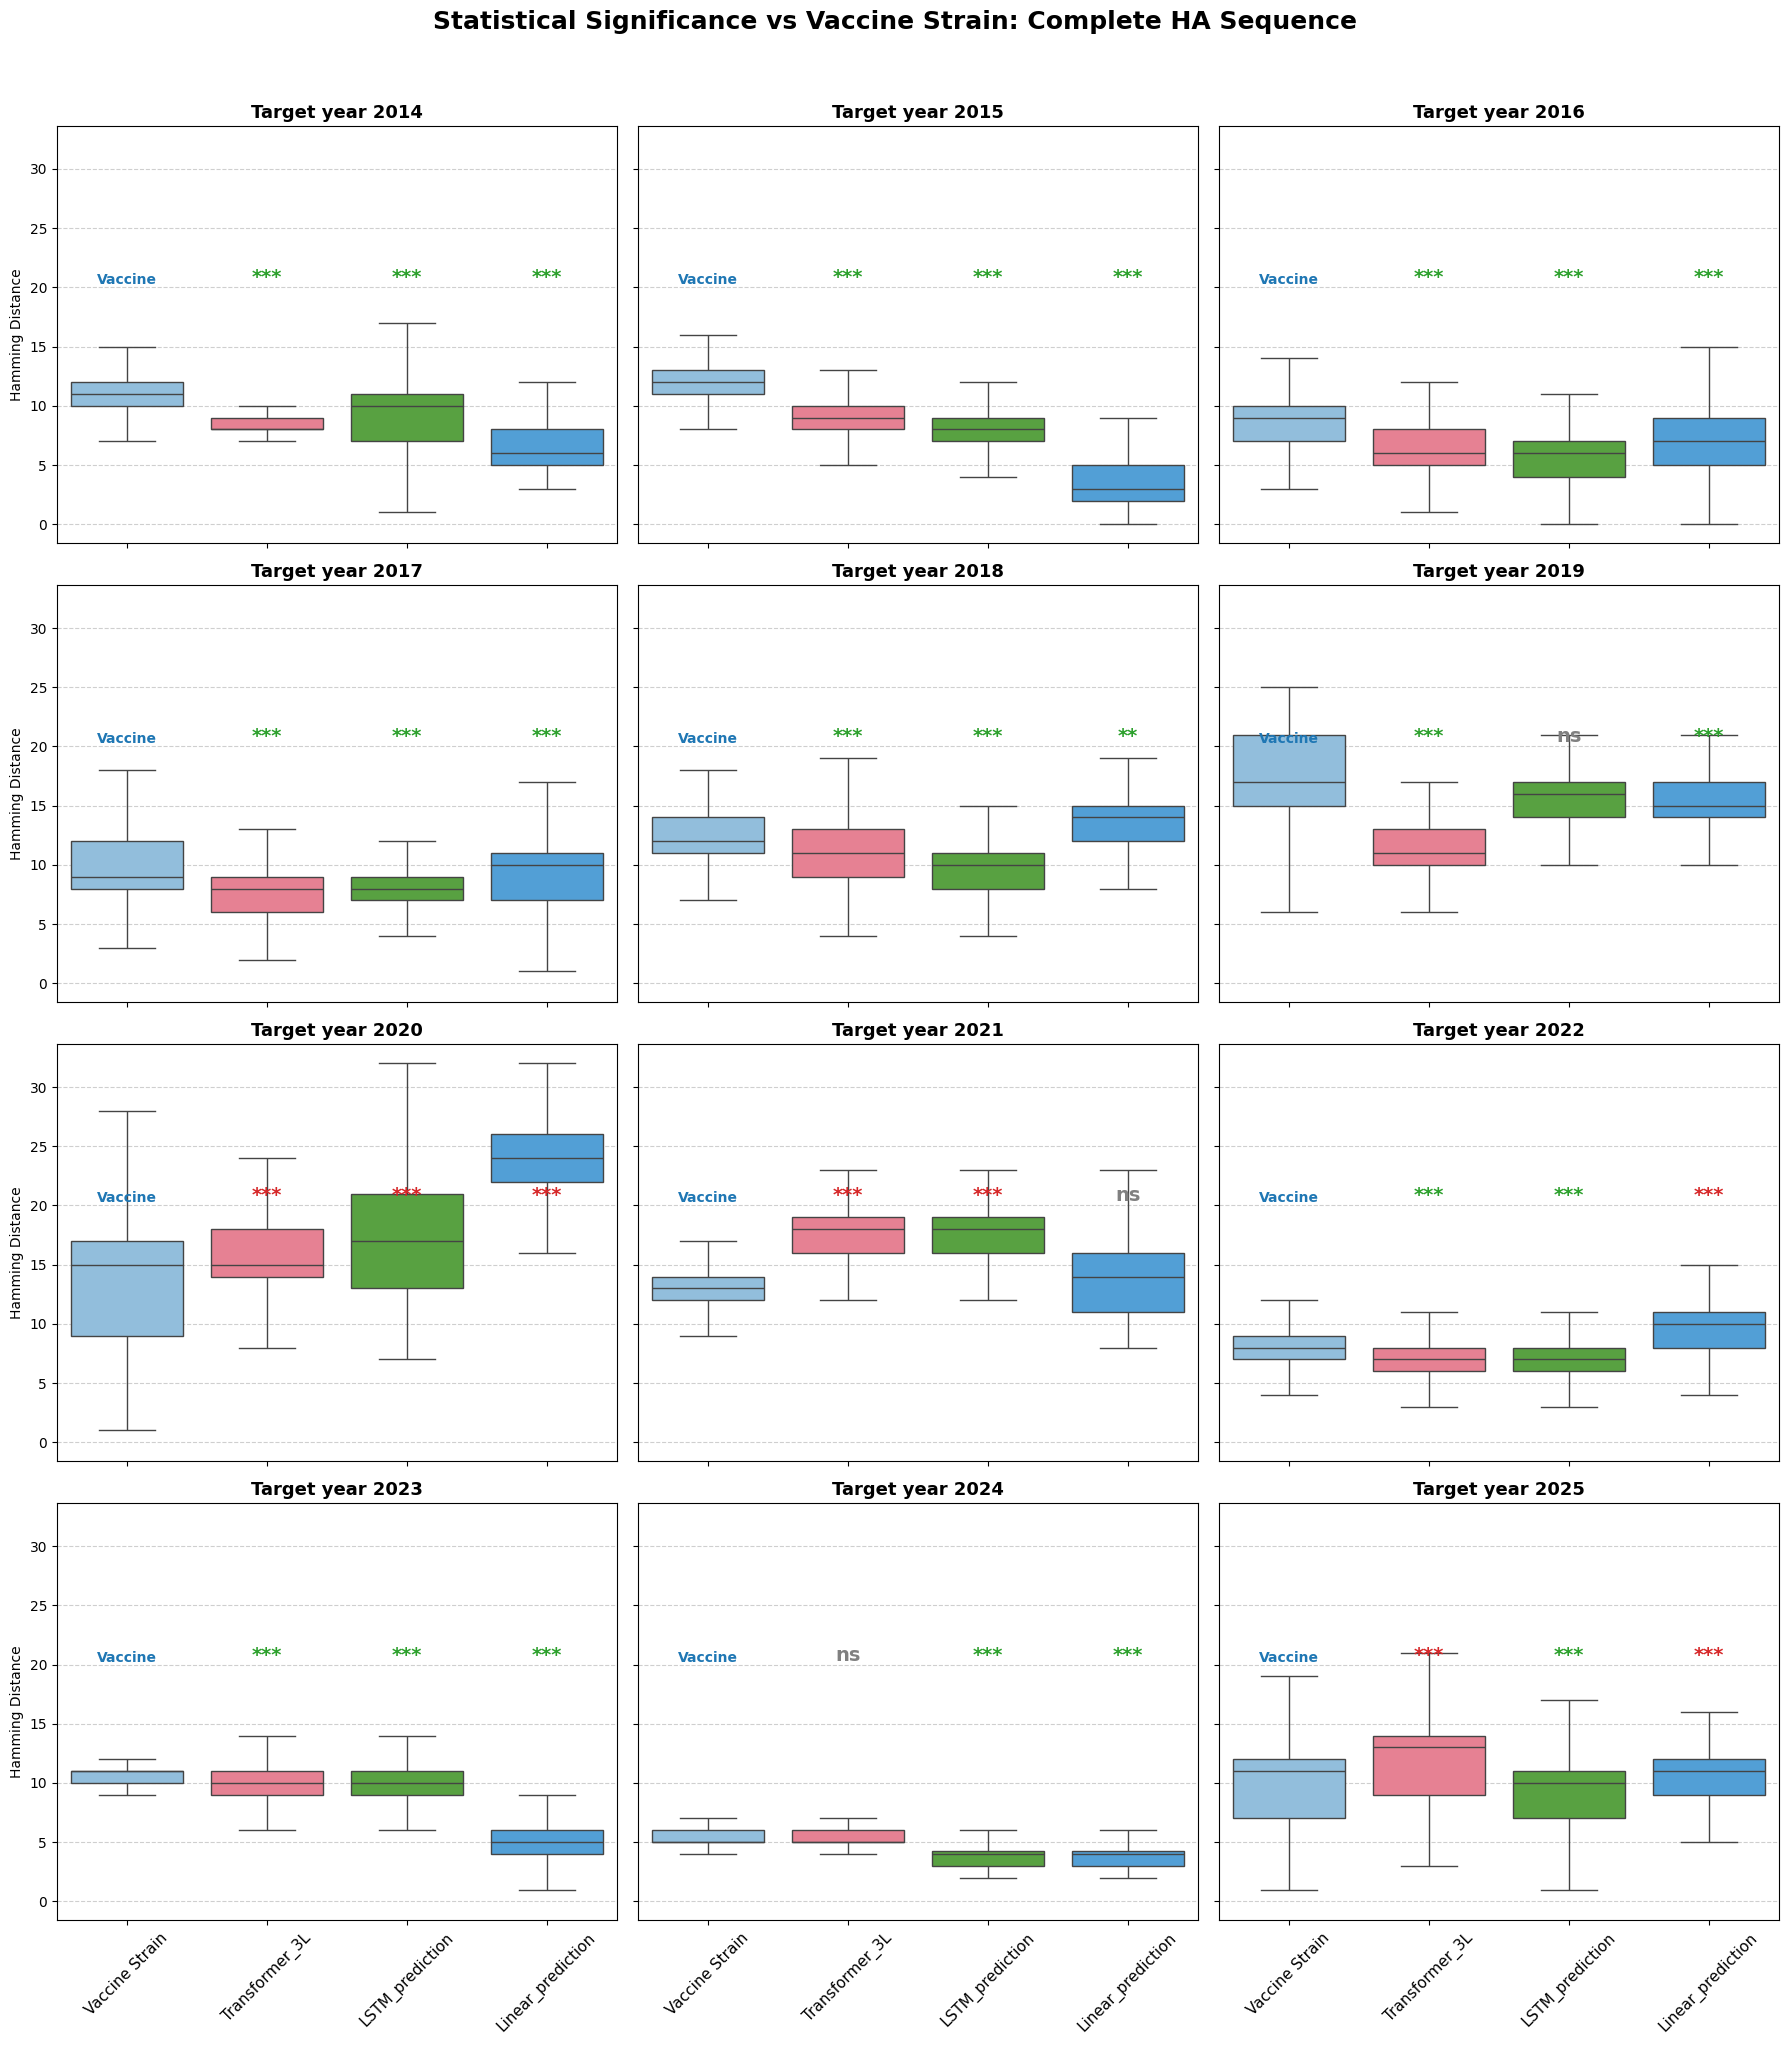

Generating Small Multiples for Epitope_Hamming...


/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean')
/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean')
/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_S

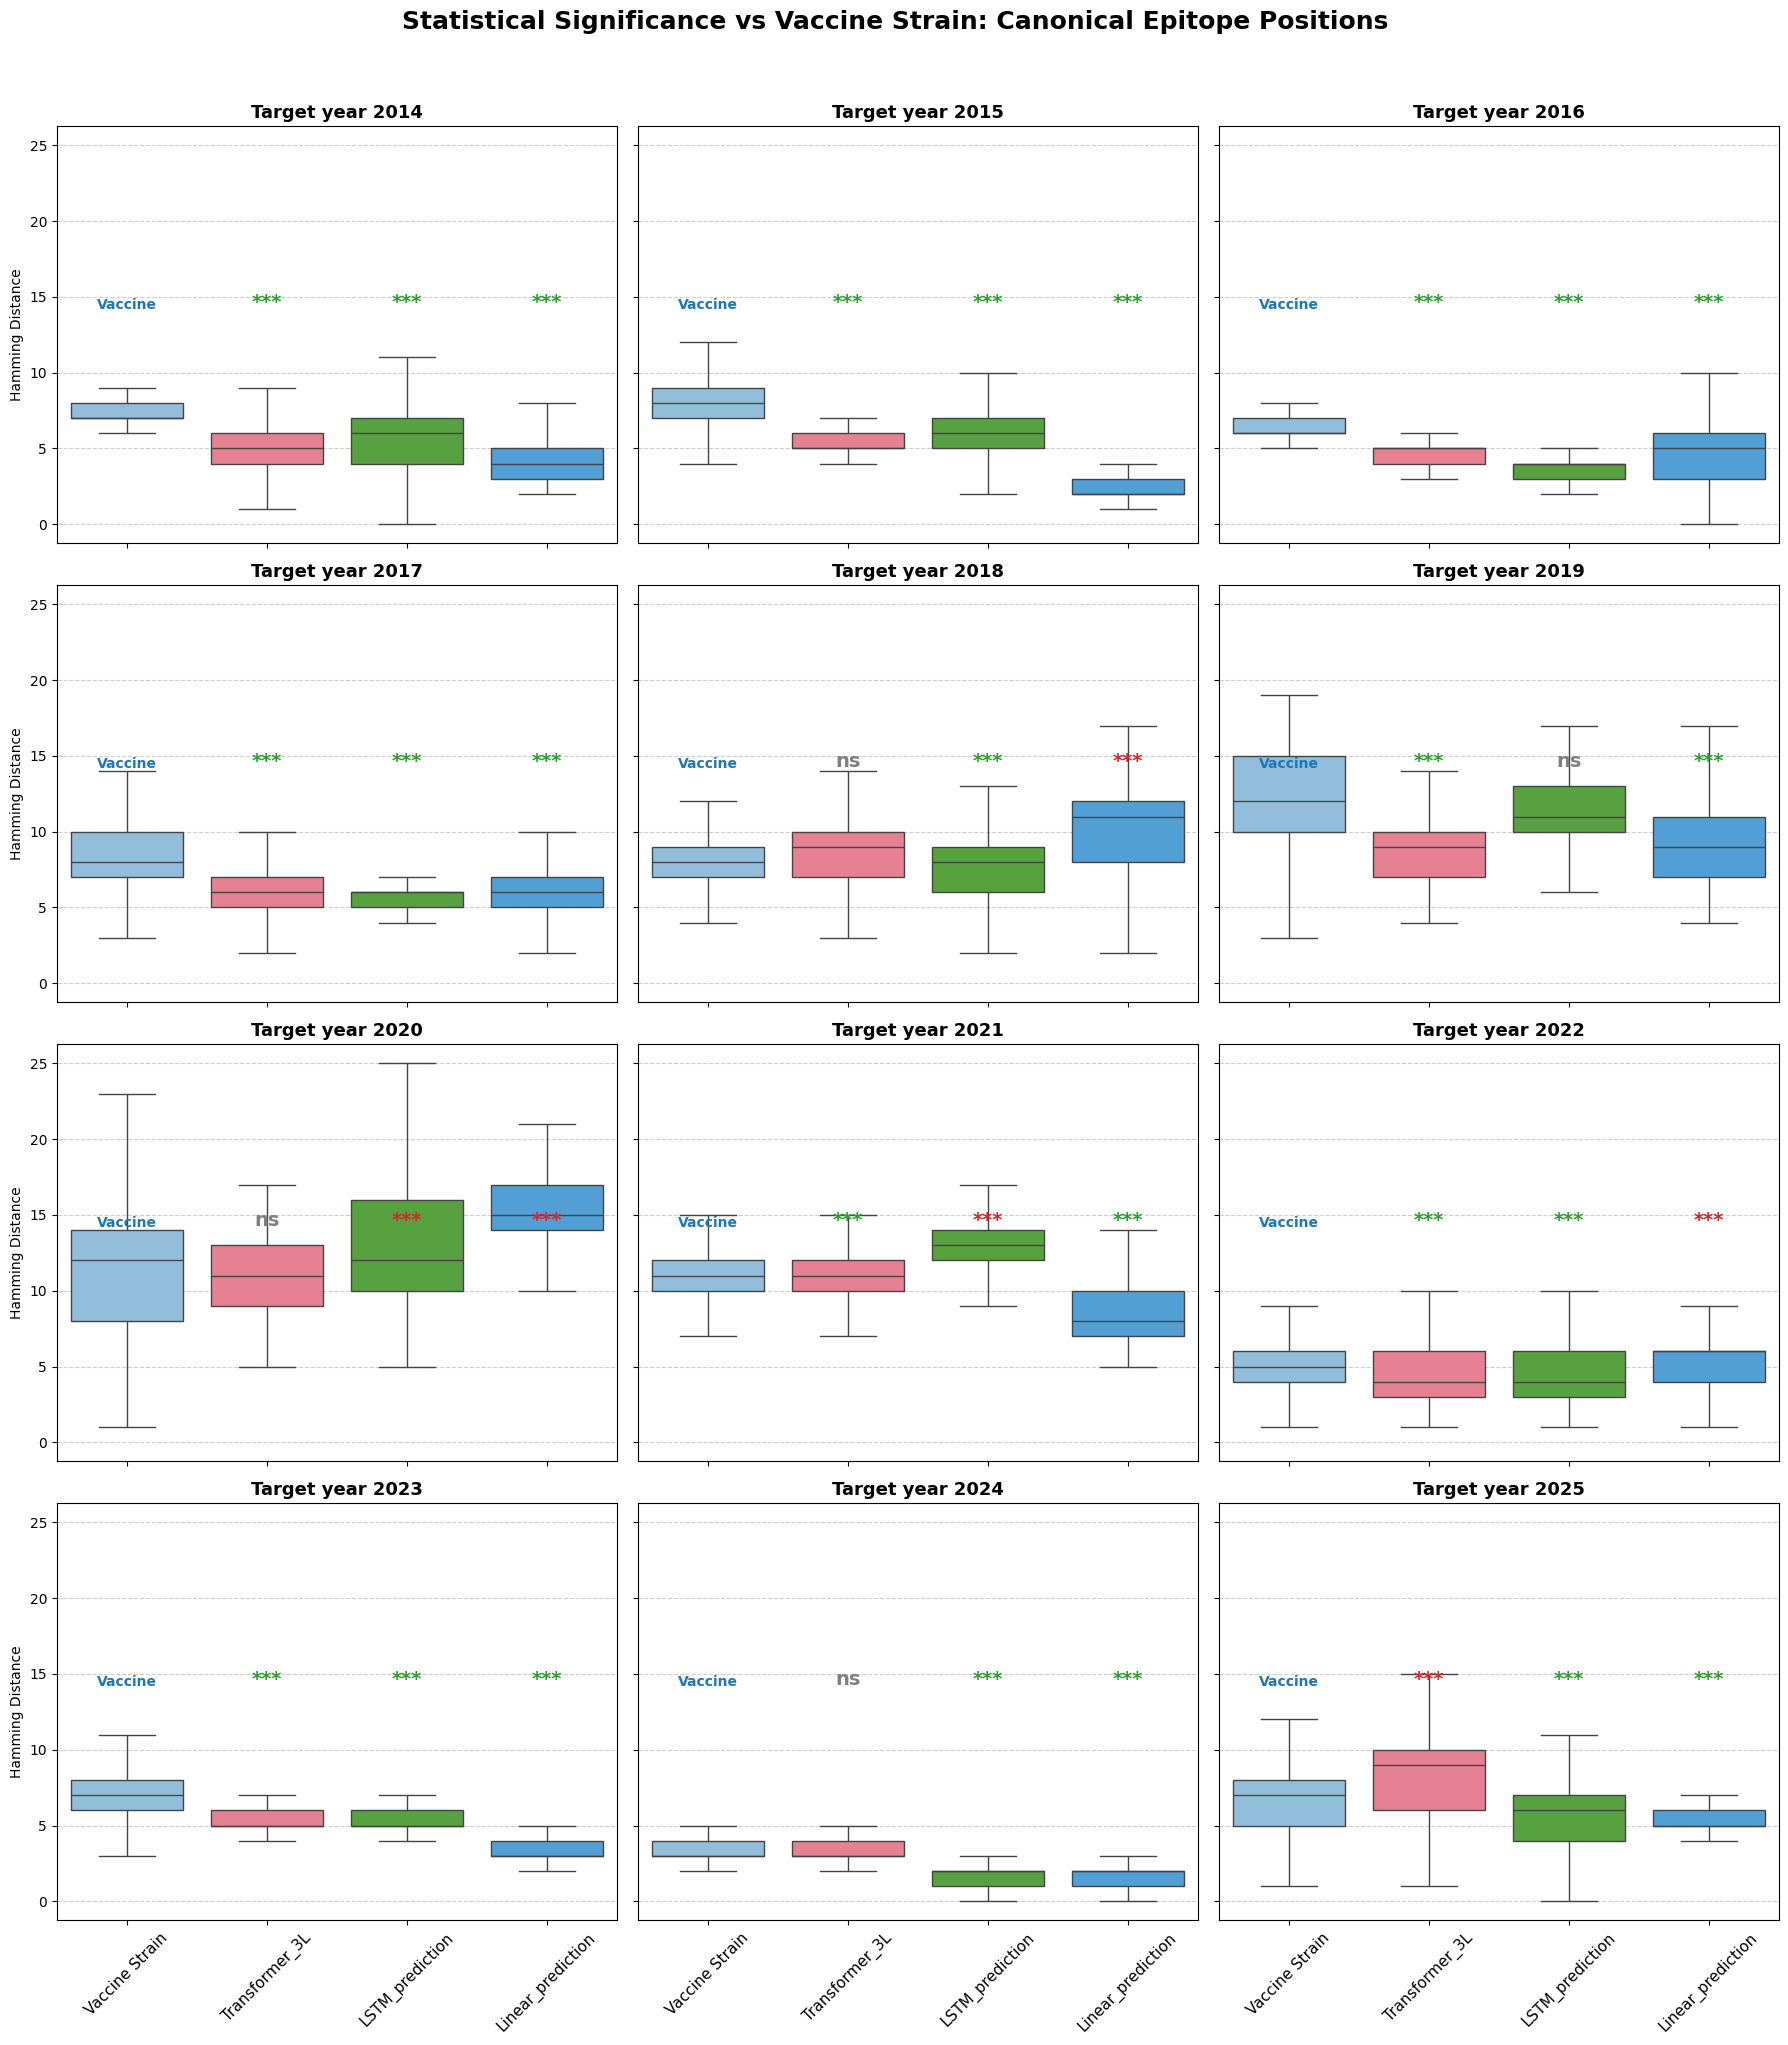

Generating Small Multiples for Shift_Hamming...


/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean')
/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean')
/tmp/ipykernel_141773/1106533813.py:97: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_pivot = df_season.pivot_table(index='Test_S

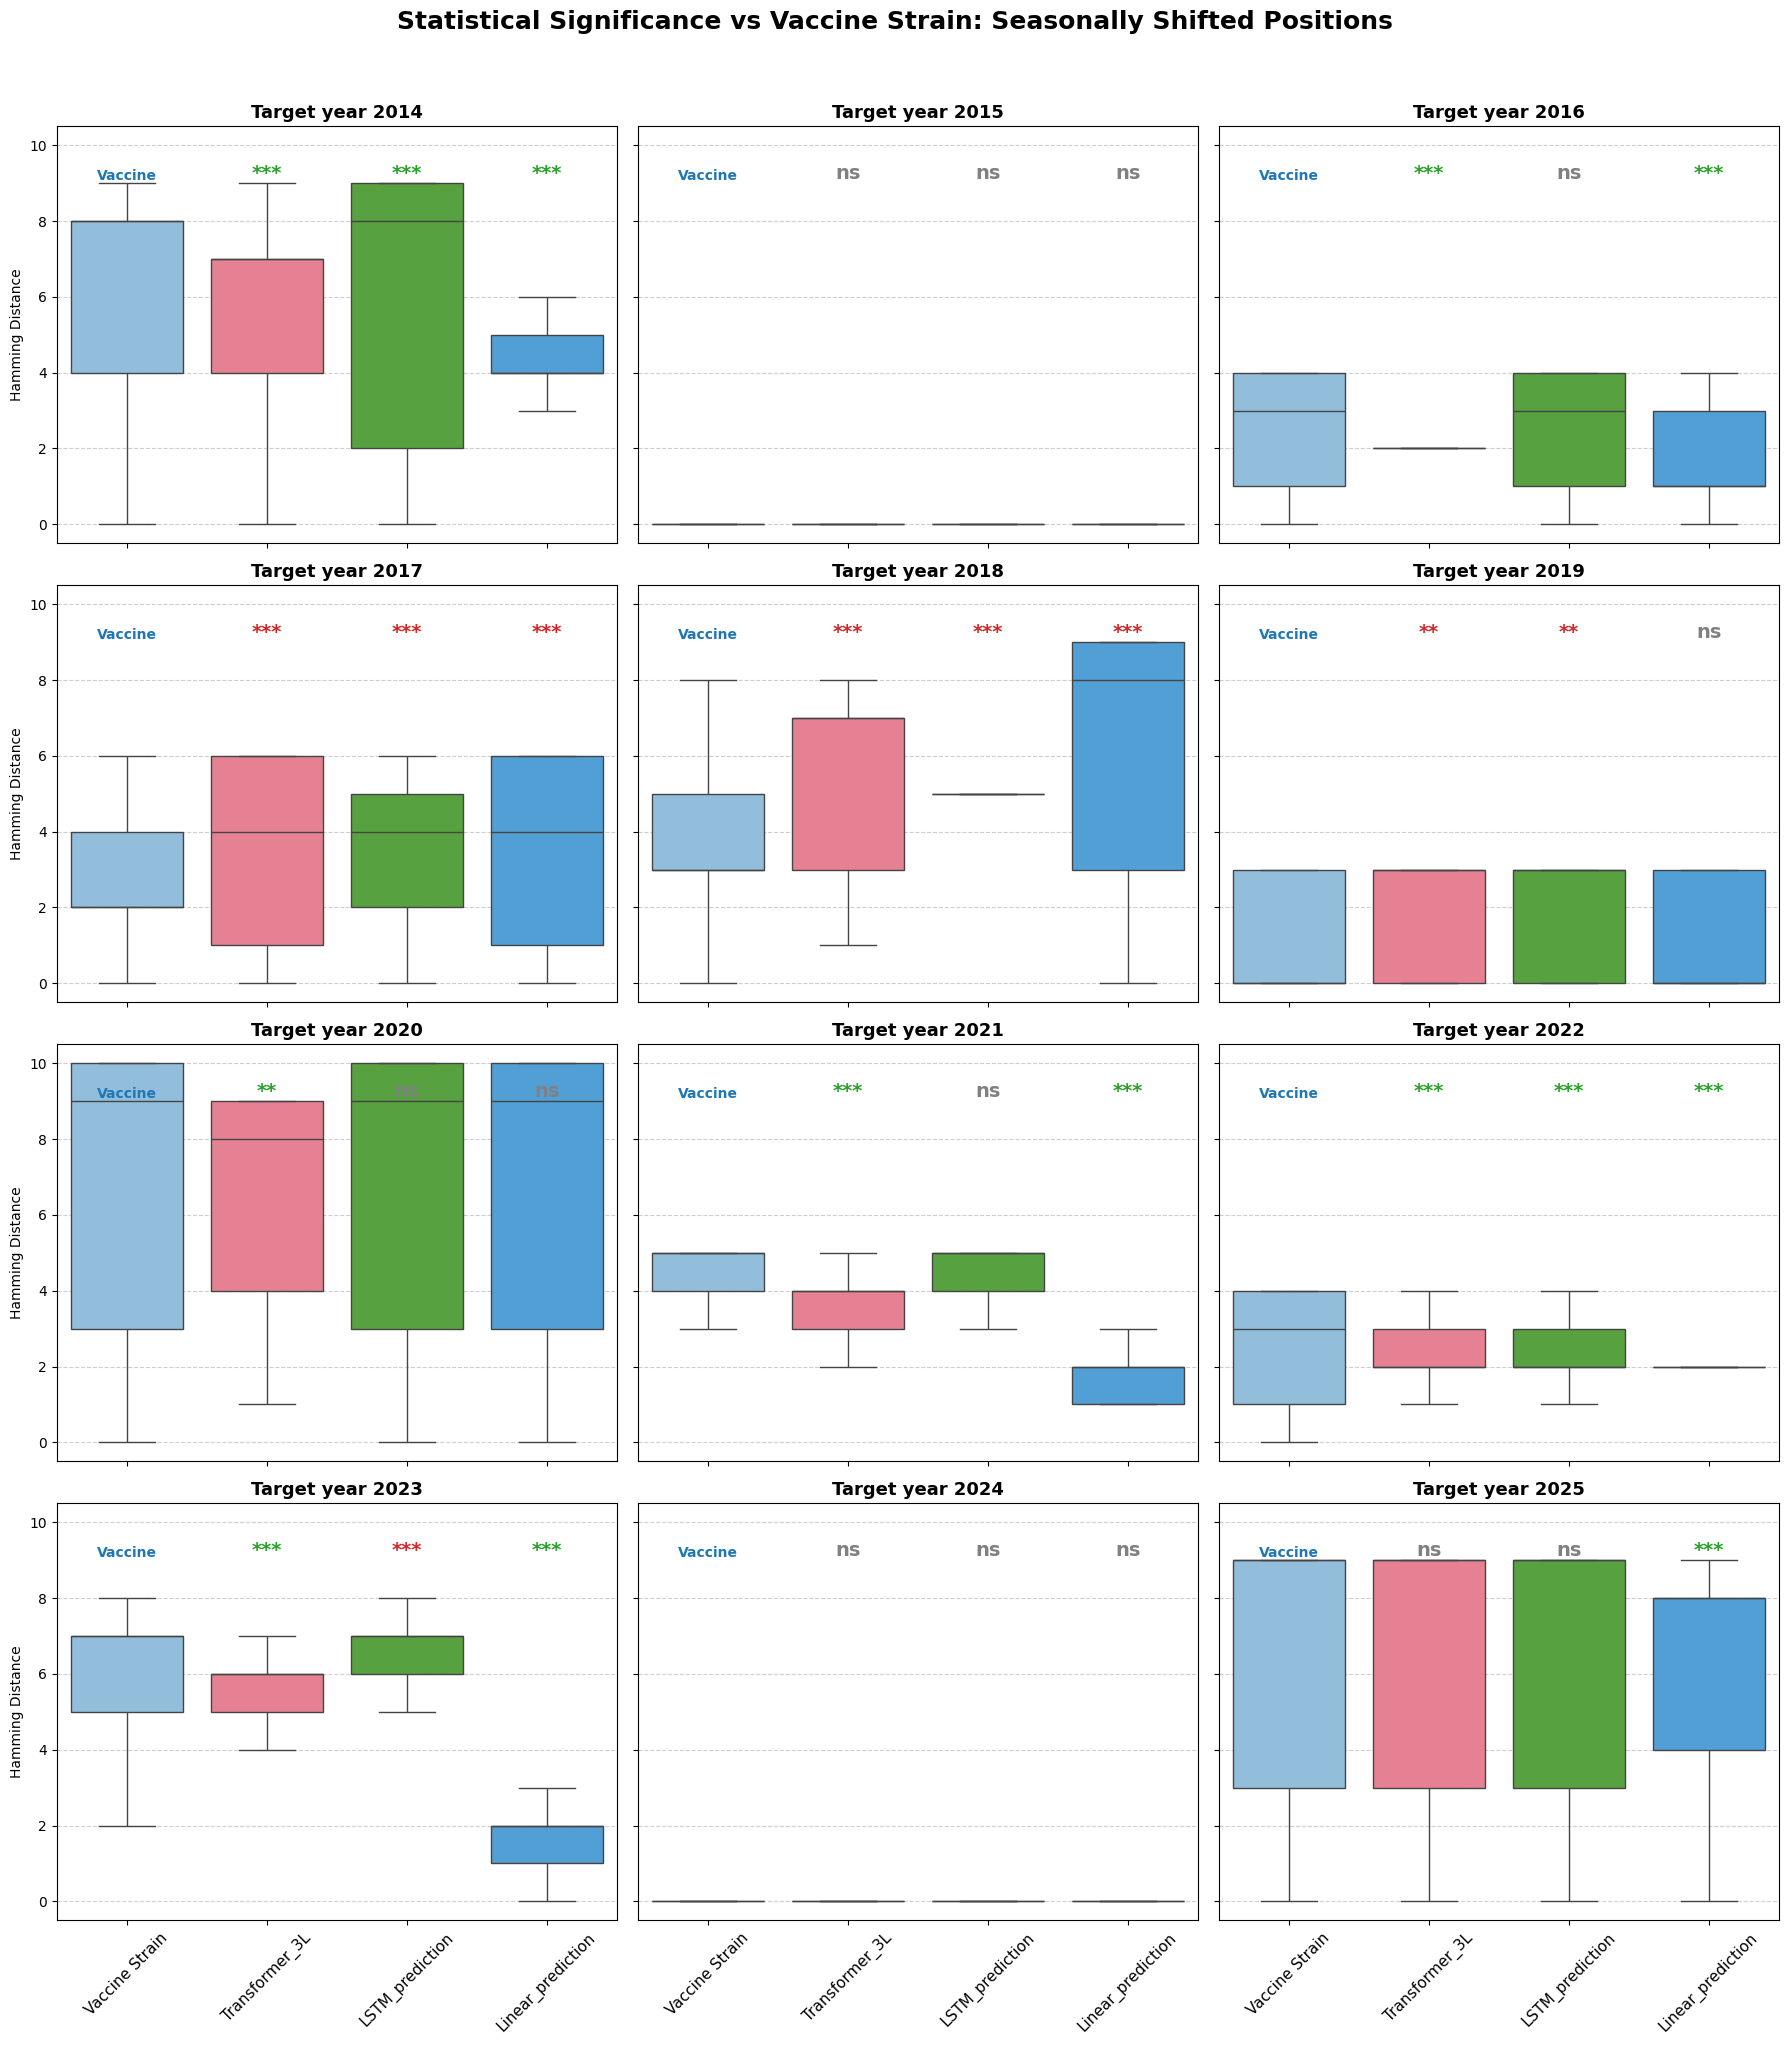

In [7]:
metrics_to_plot = ['AllPos_Hamming', 'Epitope_Hamming','Shift_Hamming']
all_stats_records = []  # Master list to hold our p-values

for metric in metrics_to_plot:
    if metric in df2.columns:
        plot_seasonal_small_multiples(df2, metric, all_stats_records)
    else:
        print(f"Skipping {metric} - Column not found in CSV.")



In [8]:
# Create a DataFrame from the collected stats and export to CSV
df_stats = pd.DataFrame(all_stats_records)
print(df_stats.head())

# Save the final file
stats_filename = "Statistical_Significance_Summary.csv"
df_stats.to_csv(stats_filename, index=False)
print(f"\nSuccessfully exported all statistical results to {stats_filename}!")

           Metric  Season              Model  Baseline_Median  Model_Median  \
0  AllPos_Hamming    2014     Transformer_3L             11.0           8.0   
1  AllPos_Hamming    2014    LSTM_prediction             11.0          10.0   
2  AllPos_Hamming    2014  Linear_prediction             11.0           6.0   
3  AllPos_Hamming    2015     Transformer_3L             12.0           9.0   
4  AllPos_Hamming    2015    LSTM_prediction             12.0           8.0   

     P_Value_Raw  P_Value_Bonferroni Significance_Stars Outcome (vs Baseline)  
0  1.923325e-264       5.769976e-264                ***                   Win  
1  4.013436e-243       1.204031e-242                ***                   Win  
2  5.484769e-195       1.645431e-194                ***                   Win  
3   7.592250e-93        2.277675e-92                ***                   Win  
4  2.530952e-187       7.592856e-187                ***                   Win  

Successfully exported all statistical result

In [18]:
# ==========================================
# 0. FASTA HELPER FOR UNIQUE SEQUENCES
# ==========================================
def load_fasta_metadata(fasta_path):
    print(f"Loading FASTA metadata from: {fasta_path}...")
    records = []
    for record in SeqIO.parse(fasta_path, "fasta"):
        fields = record.description.split('|')
        zone = fields[-1].strip() if len(fields) > 1 else 'Global'
        sequence = str(record.seq).replace('-', '').replace('*', '')
        records.append({'Test_Seq_ID': record.description, 'Sequence': sequence, 'Zone': zone})
    return pd.DataFrame(records)

# ==========================================
# 1. LOAD AND PREP DATA
# ==========================================
# Load Distances
df = pd.read_csv('h3n2_clean/h3n2_clean_LV/5_Raw_Hamming_Distances.csv')

# Load FASTA & Merge (UPDATE THIS PATH TO YOUR MASTER FASTA)
master_fasta = 'h3n2_clean.fasta' 
df_meta = load_fasta_metadata(master_fasta)
df = df.merge(df_meta, on='Test_Seq_ID', how='left')

# --- FILTER FOR UNIQUE SEQUENCES ---
# 1. Get all combinations of Season, Test_Seq_ID, Sequence, and Zone
df_unique_ids = df[['Season', 'Test_Seq_ID', 'Sequence', 'Zone']].drop_duplicates()
# 2. Drop duplicate sequences within the same Season and Zone
df_unique_ids = df_unique_ids.drop_duplicates(subset=['Season', 'Sequence', 'Zone'], keep='first')
# 3. Extract the list of Test_Seq_IDs that represent the "Unique" cohort
unique_test_seq_ids = df_unique_ids['Test_Seq_ID'].tolist()
# 4. Filter the main dataframe to ONLY include these unique IDs
df = df[df['Test_Seq_ID'].isin(unique_test_seq_ids)].copy()
print(f"Filtered dataset to {len(unique_test_seq_ids)} unique sequence IDs.")

# ==========================================
# NEW: EXPORT THE UNIQUE SEQUENCE MAPPING
# ==========================================
# Create a clean dataframe for export
df_unique_export = df_unique_ids[['Season', 'Zone', 'Test_Seq_ID', 'Sequence']].copy()

# Extract just the EPI_ISL cleanly from the header (e.g., ">EPI_ISL_12345|..." -> "EPI_ISL_12345")
df_unique_export['EPI_ISL'] = df_unique_export['Test_Seq_ID'].apply(lambda x: str(x).split('|')[0].replace('>', ''))

# Reorder columns to make EPI_ISL easily visible at the front
df_unique_export = df_unique_export[['Season', 'Zone', 'EPI_ISL', 'Test_Seq_ID', 'Sequence']]

# Save it to a CSV
export_filename = "Unique_Sequences_Mapping.csv"
df_unique_export.to_csv(export_filename, index=False)
print(f"✅ Saved unique sequence IDs to '{export_filename}' for future use!")
# ==========================================

Filtered dataset to 33189 unique sequence IDs.
✅ Saved unique sequence IDs to 'Unique_Sequences_Mapping.csv' for future use!


Generating Small Multiples for AllPos_Hamming (Unique Sequences)...


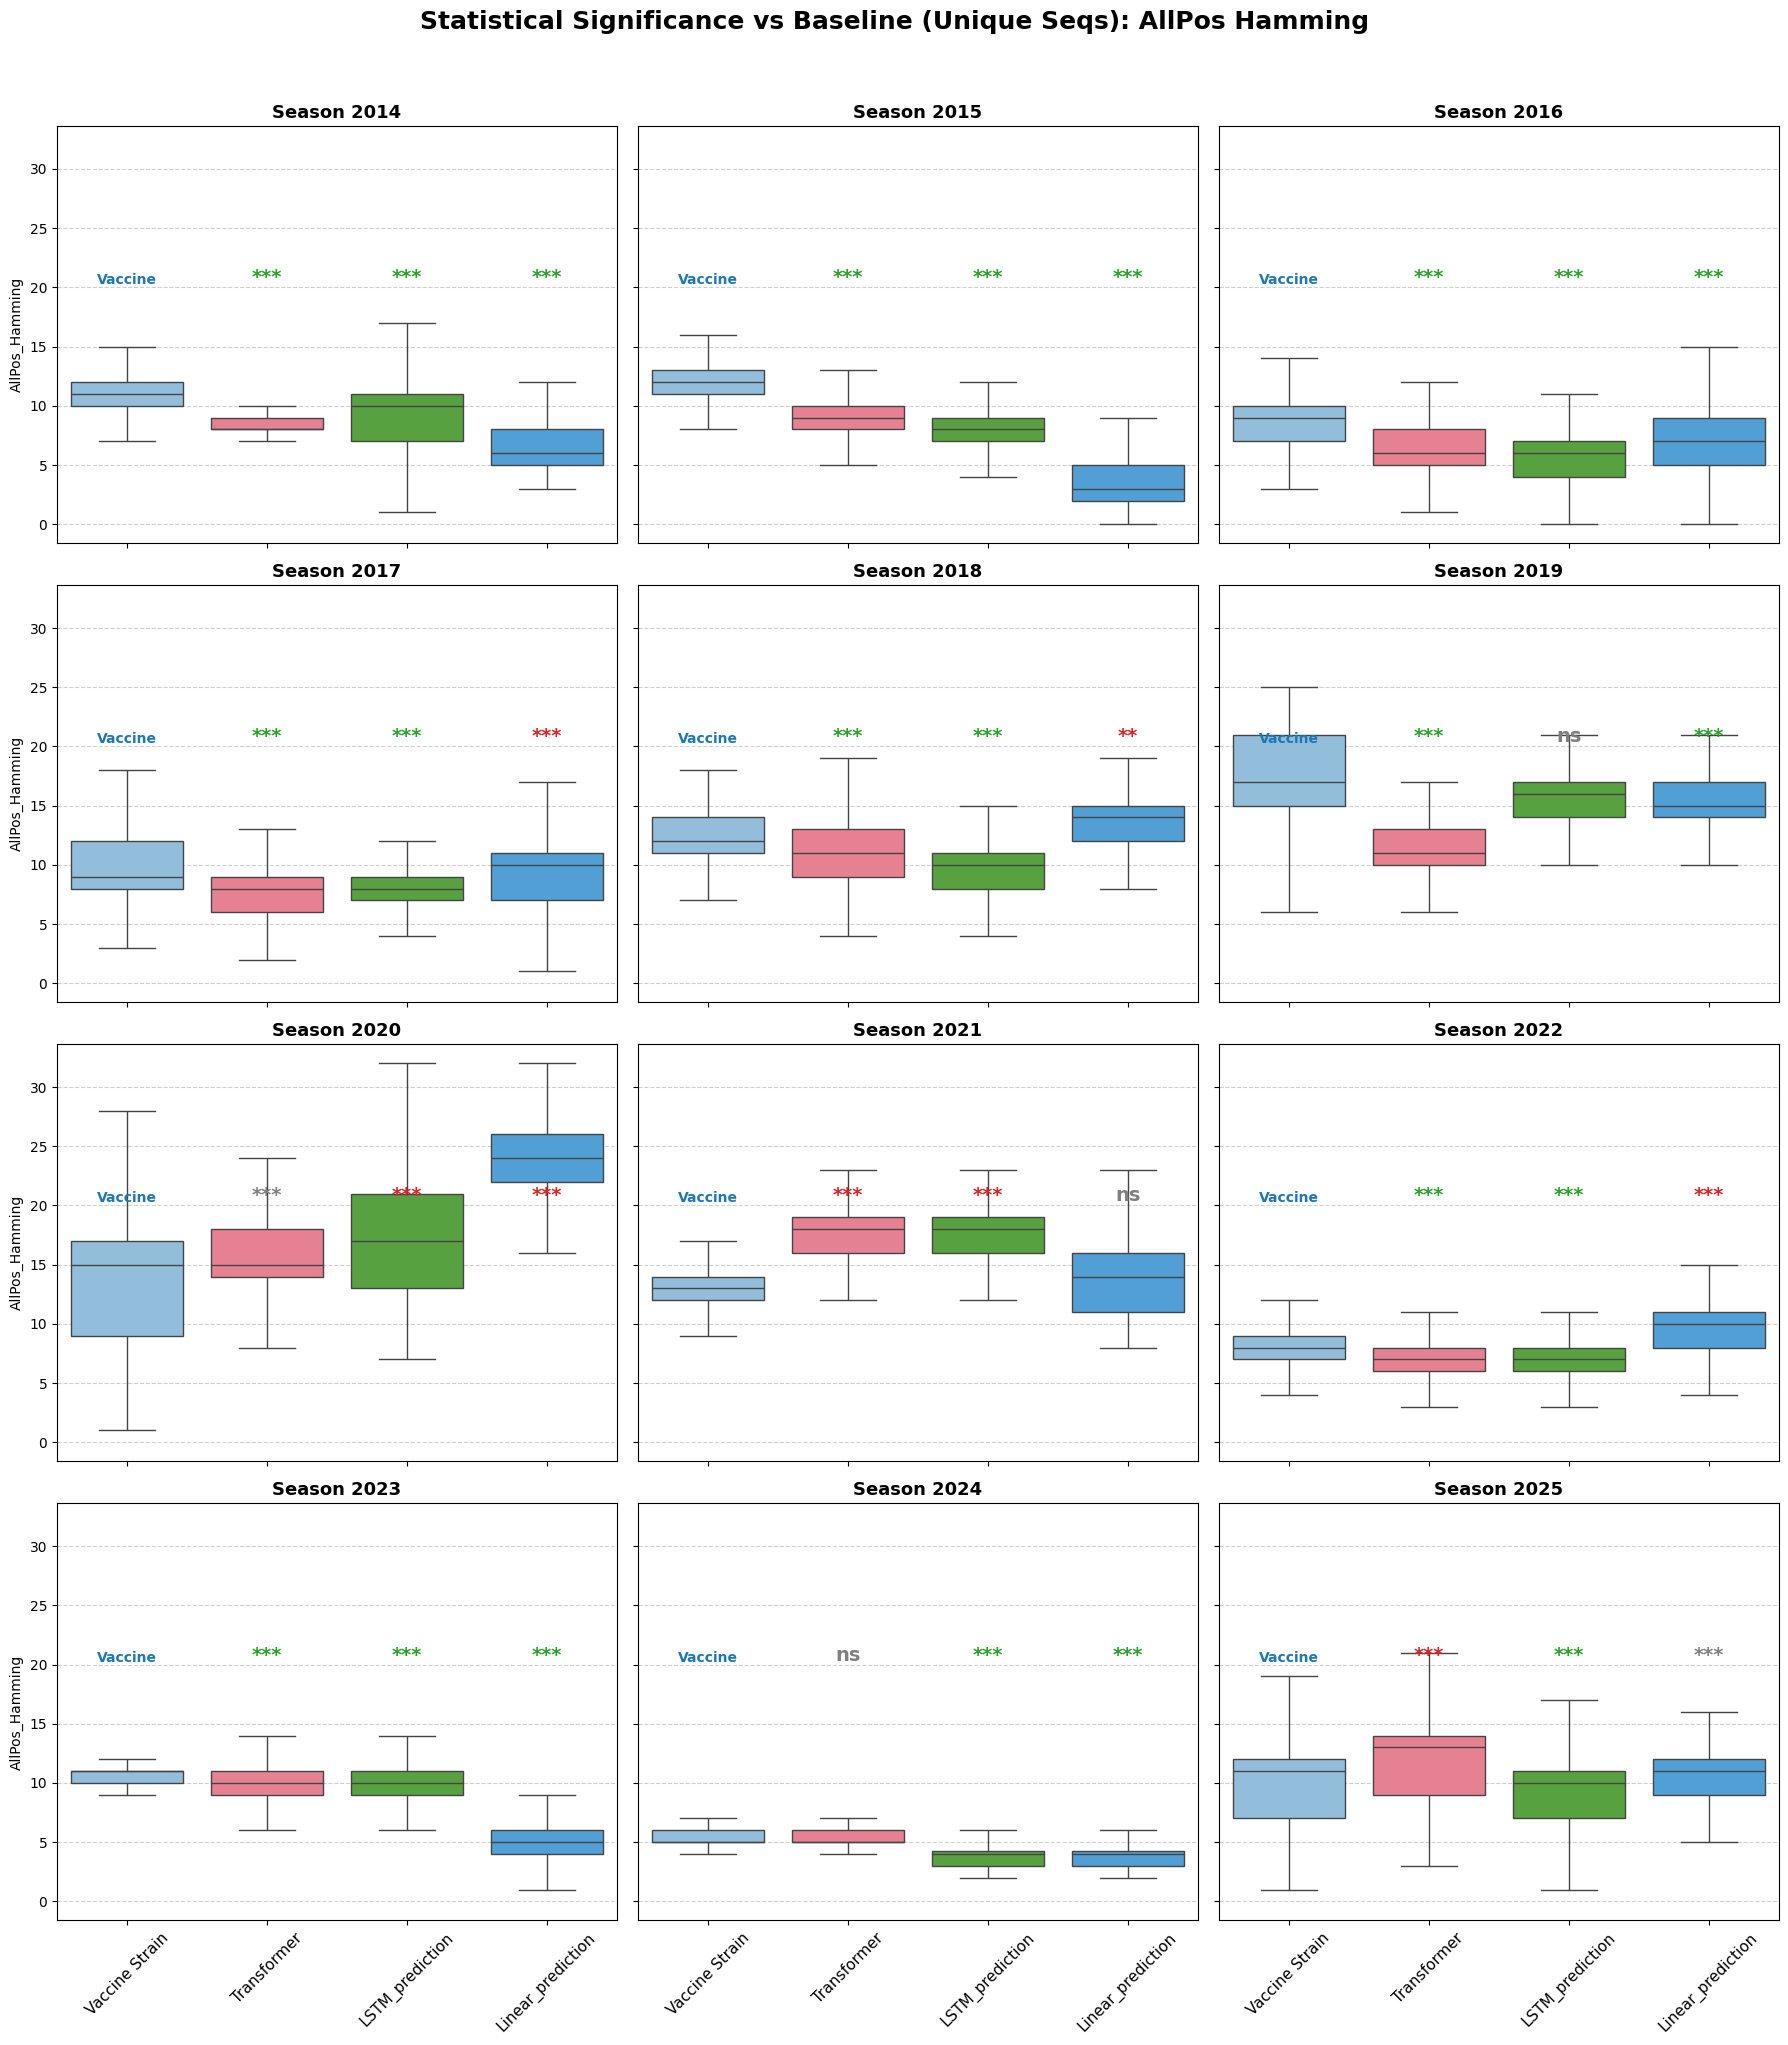

Generating Small Multiples for Epitope_Hamming (Unique Sequences)...


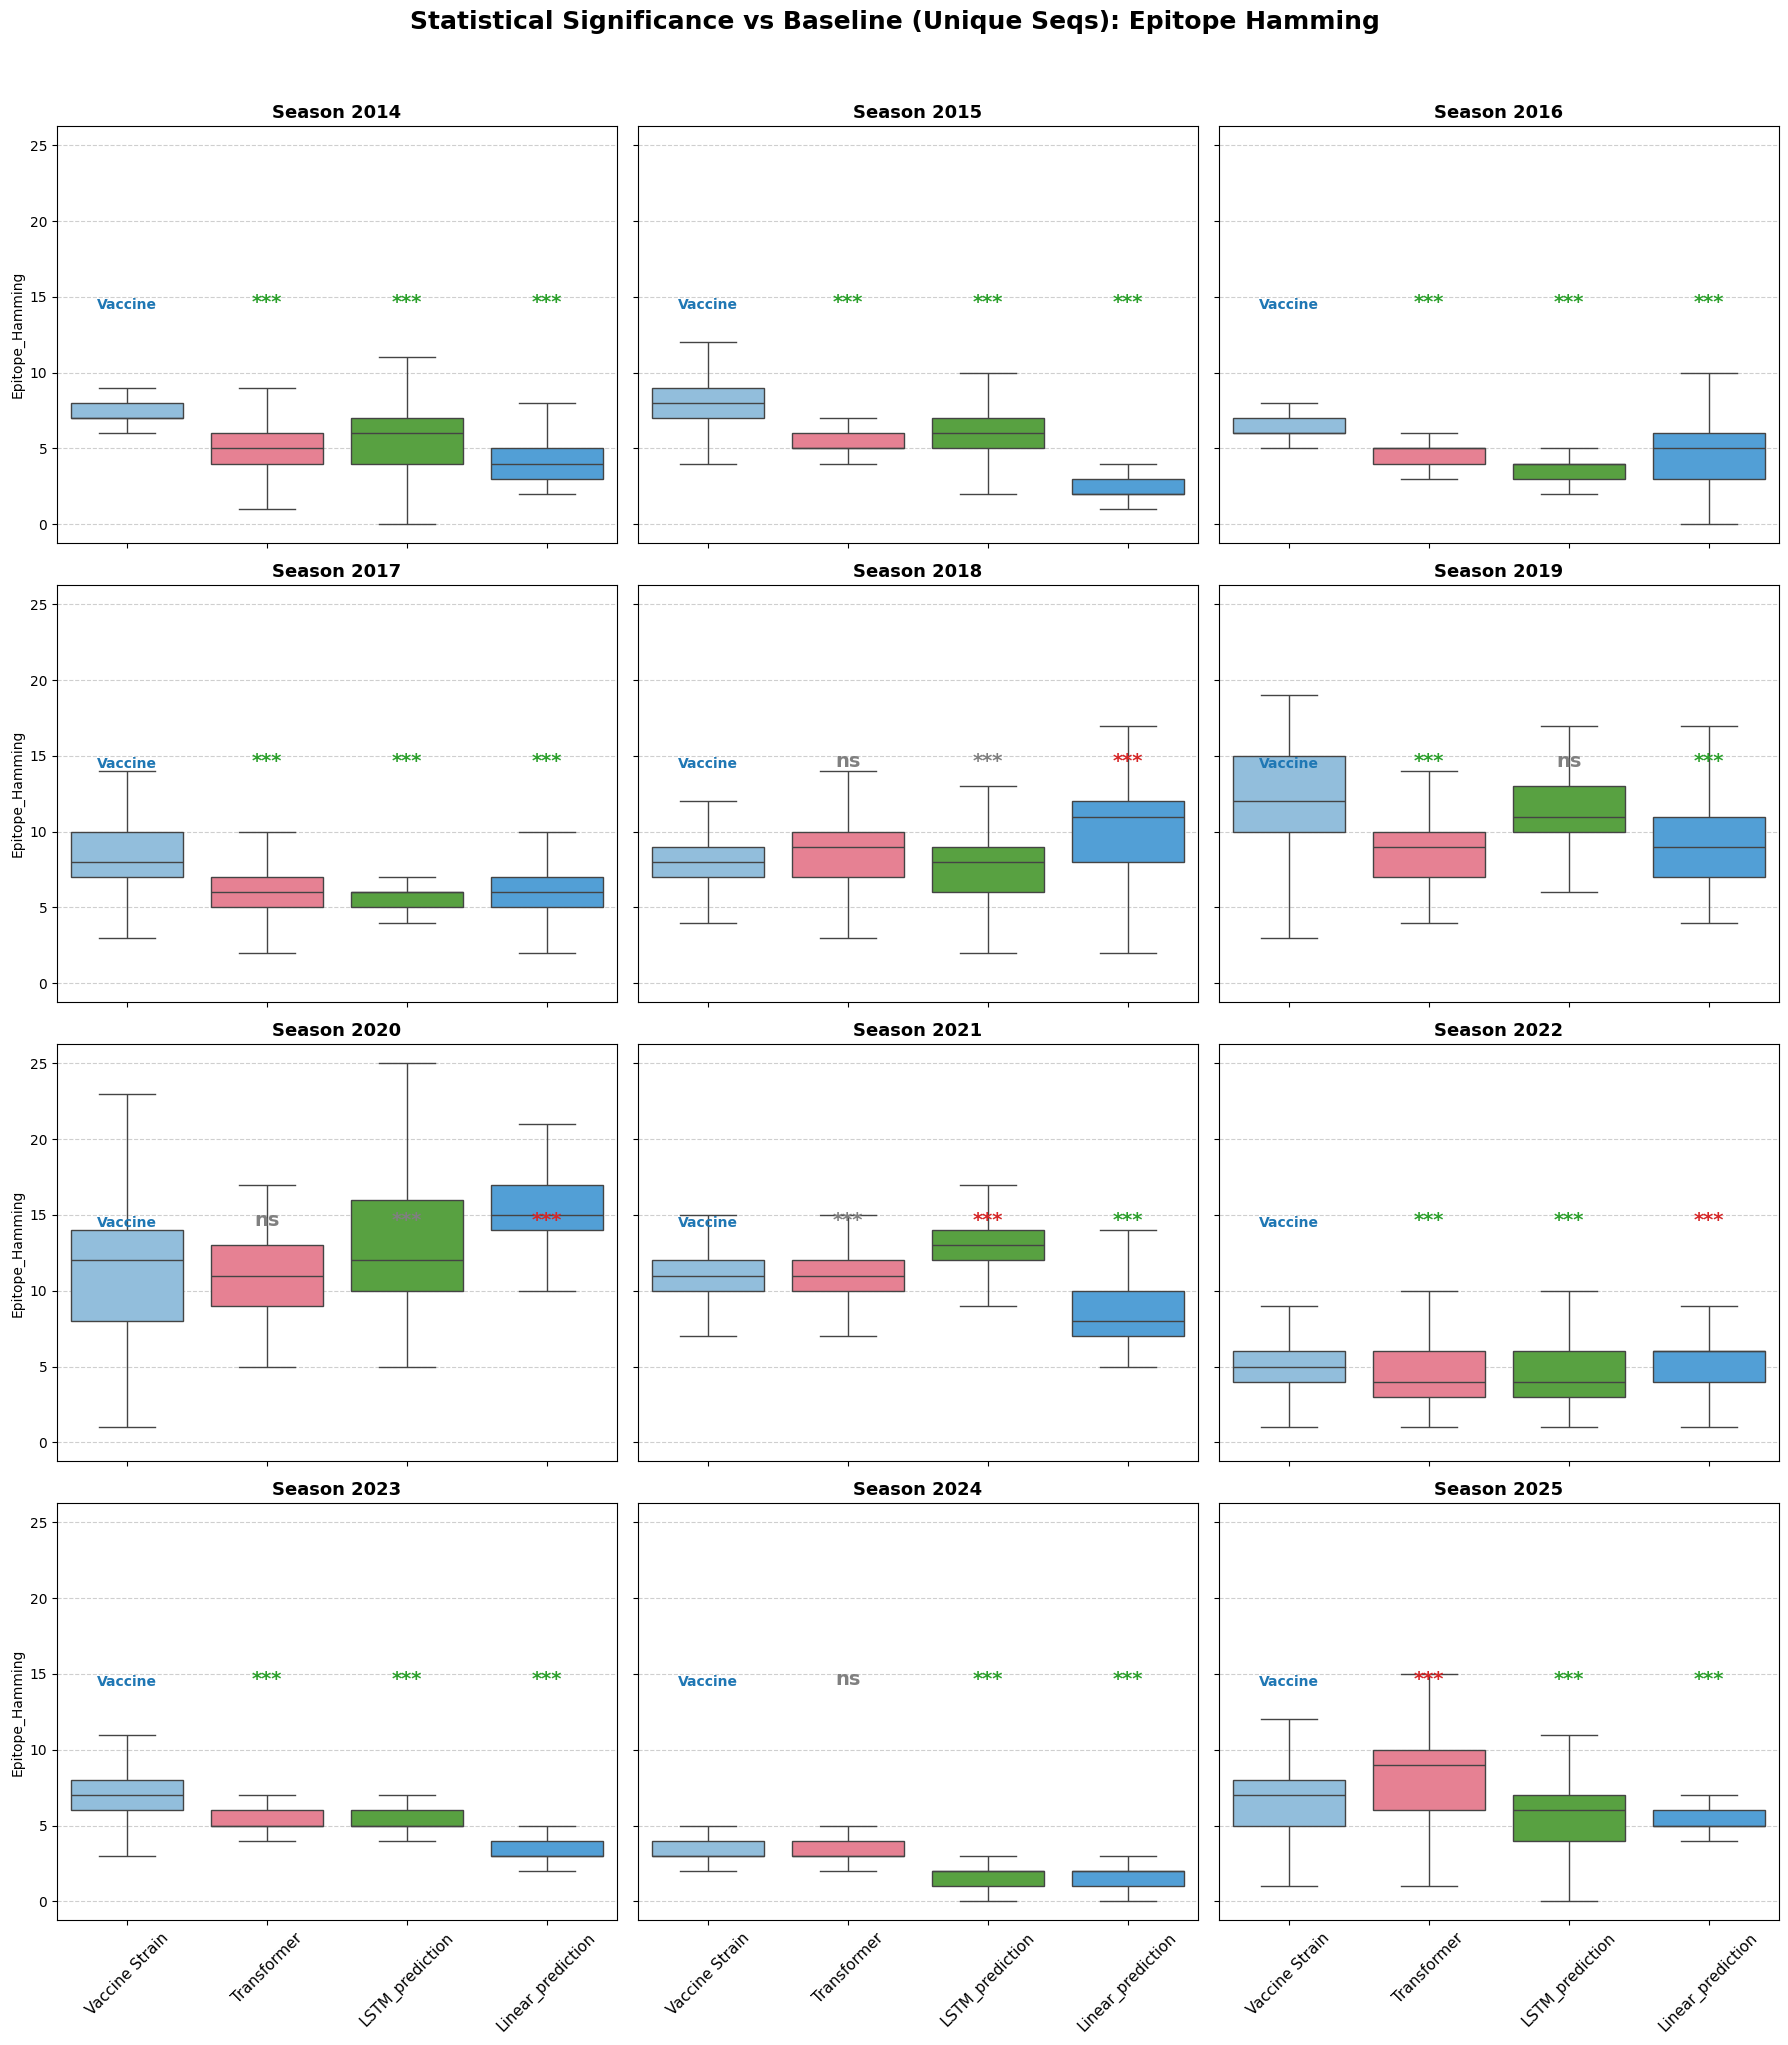

Generating Small Multiples for Shift_Hamming (Unique Sequences)...


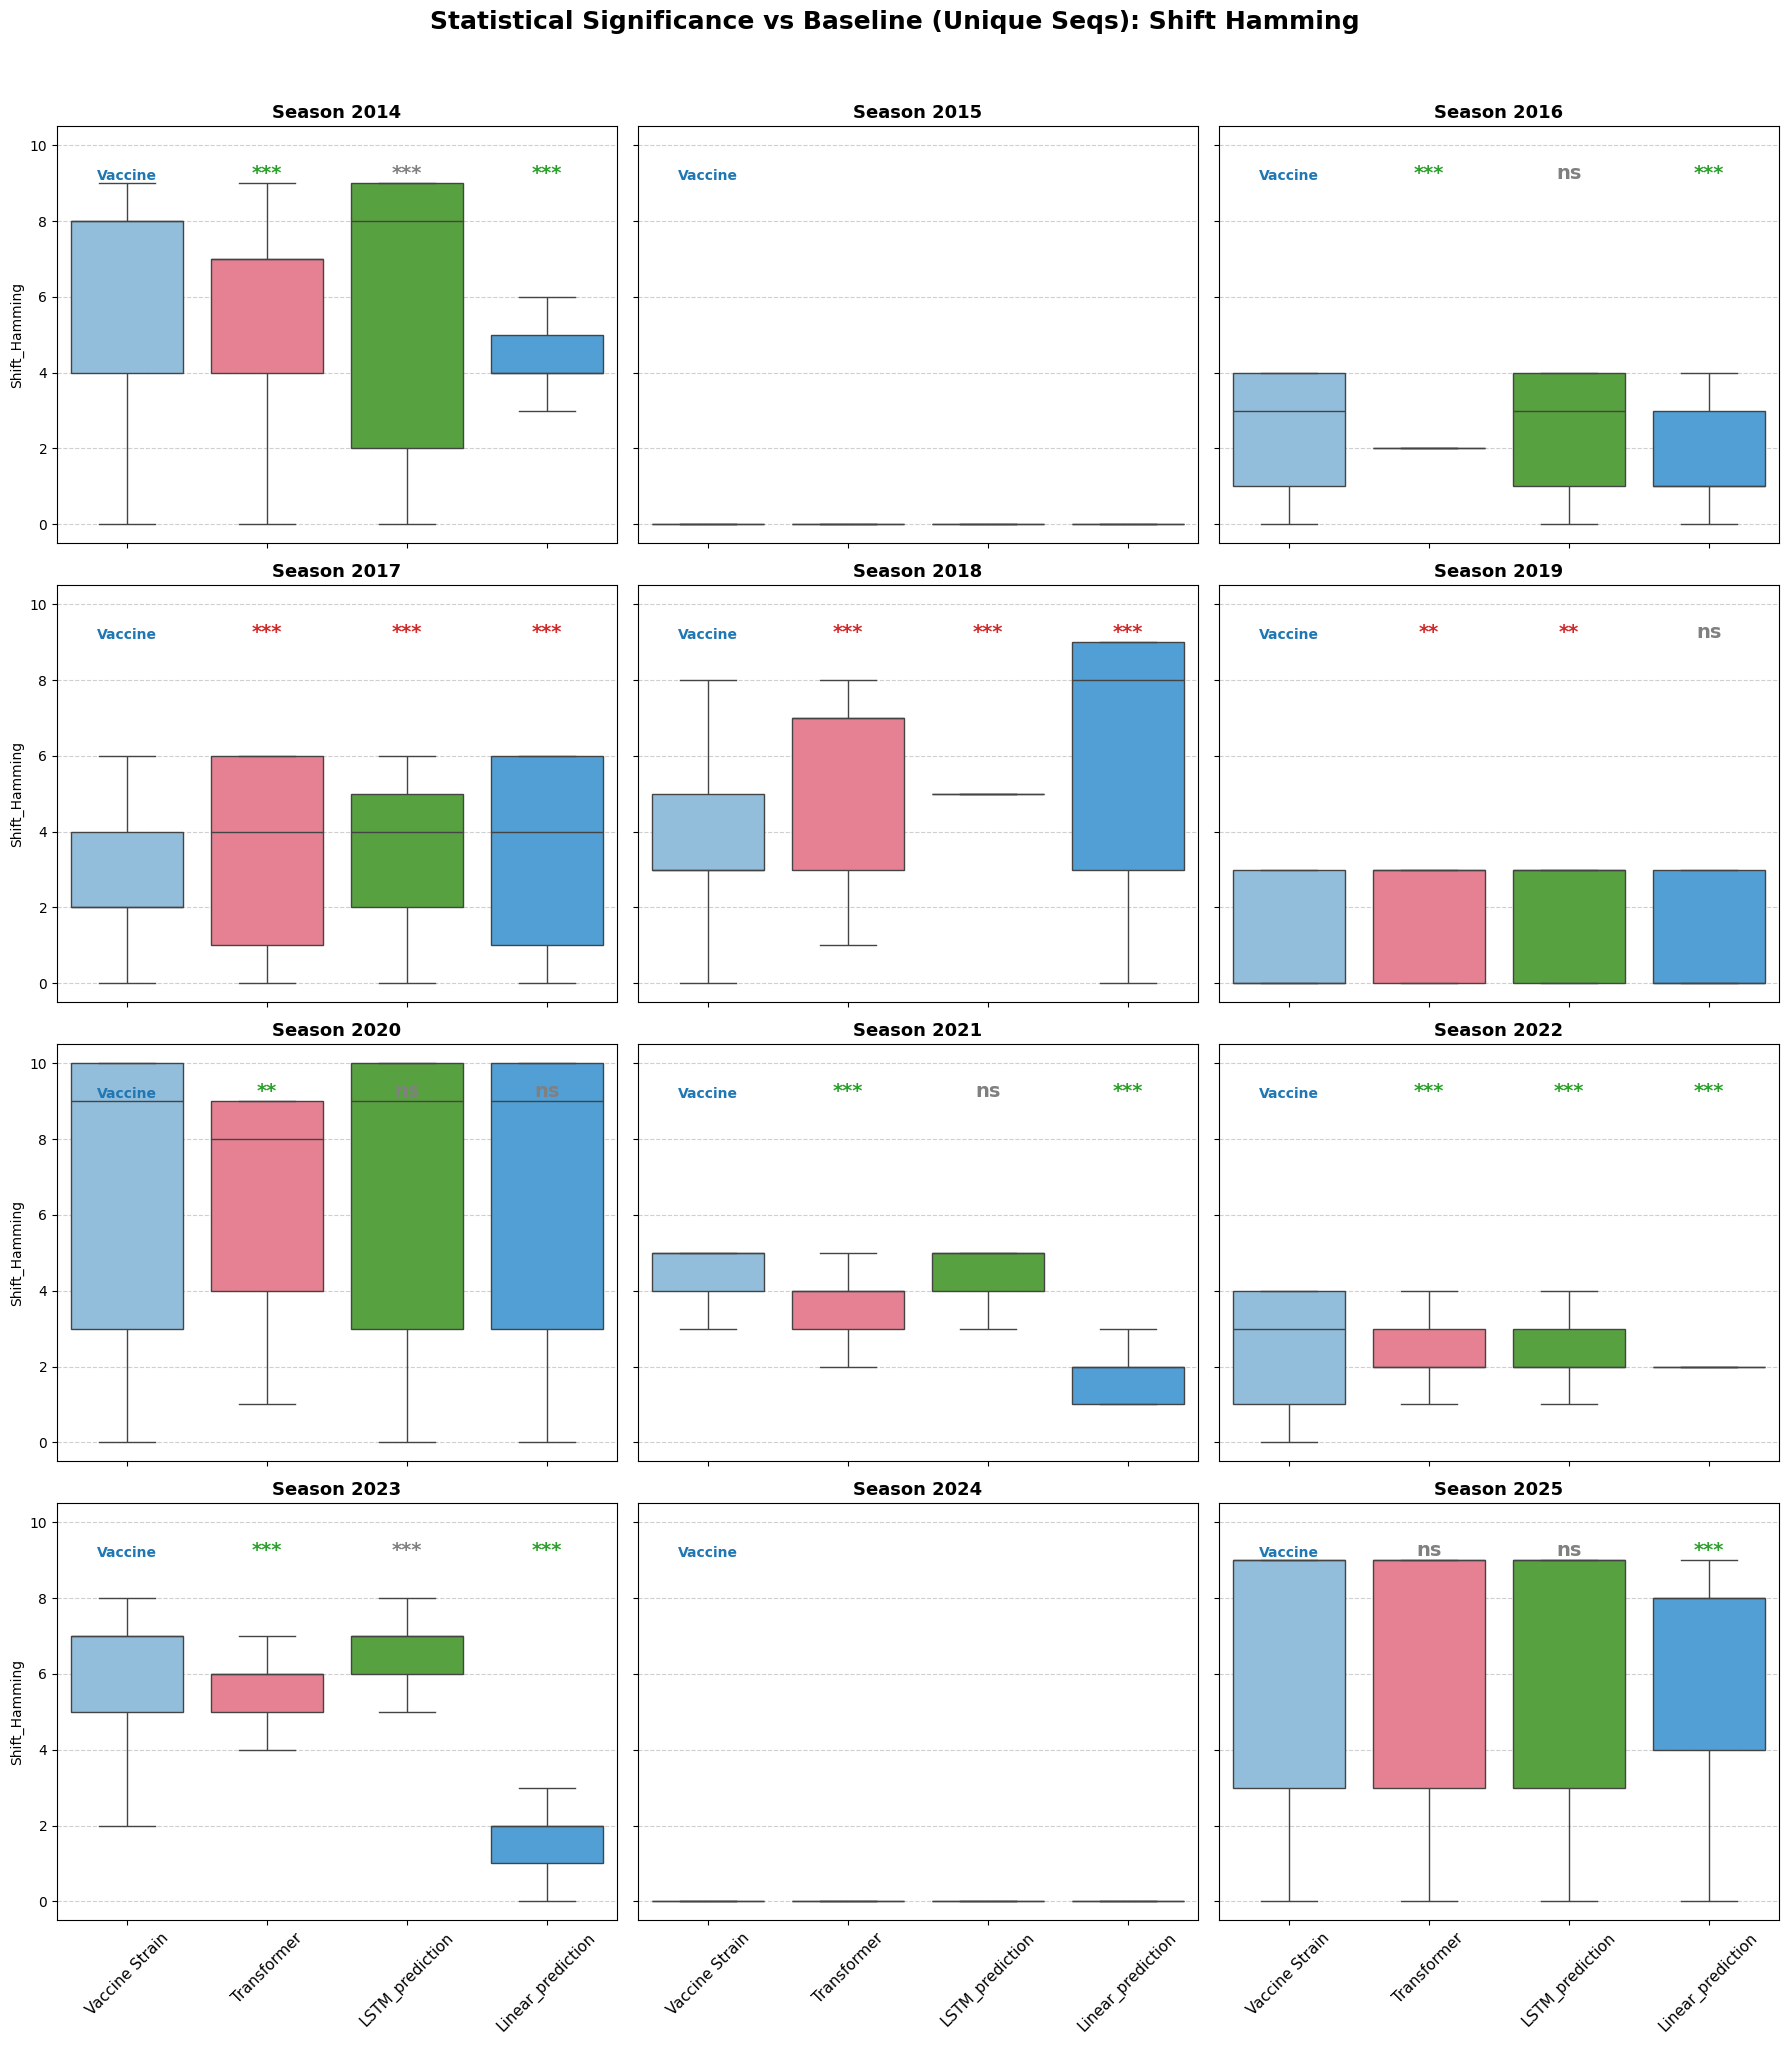


Successfully exported all unique statistical results to Statistical_Significance_Summary_Unique.csv!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon
import math
from Bio import SeqIO

# Future scripts will just be this easy:
df_dist = pd.read_csv('h3n2_clean/h3n2_clean_LV/5_Raw_Hamming_Distances.csv')
df_uniq_map = pd.read_csv('Unique_Sequences_Mapping.csv')

# Merge to get the 'Zone' and identify which ones are unique!
df = df_dist.merge(df_uniq_map[['Season', 'Test_Seq_ID', 'Zone', 'EPI_ISL']], on=['Season', 'Test_Seq_ID'], how='inner')

# --- CLEAN NAMES & RANK ---
def fix_model_names(name):
    name_str = str(name).lower()
    if '_vaccine' in name_str or 'vaccine' in name_str: return 'Vaccine Strain'
    if 'hotspot' in name_str: return 'Ensemble_all'
    if 'train' in name_str: return 'Train_consensus'
    if name_str.startswith('ensemble_en'): return 'Ensemble_Entropy'
    if name_str.startswith('representative'): return 'Test_consensus'
    if 'lstm' in name_str: return 'LSTM_prediction'
    if 'linear' in name_str: return 'Linear_prediction'
    if 'transformer_3l' in name_str: return 'Transformer'
    return name

df['Model'] = df['Model'].apply(fix_model_names)
df = df[~df['Model'].str.startswith('Ensemble')]
df = df[~df['Model'].isin(['Transformer_4L', 'Transformer_5L','Train_consensus', 'Test_consensus'])].copy()


baseline_name = 'Vaccine Strain'

def get_asterisks(p_val):
    if pd.isna(p_val): return ""
    if p_val < 0.001: return "***"
    if p_val < 0.01: return "**"
    if p_val < 0.05: return "*"
    return "ns"

# Updated Ranking (Vaccine -> Transformer -> LSTM -> Linear -> Test)
def get_model_rank(name):
    name_str = str(name).lower()
    if 'vaccine' in name_str: return 0
    elif 'transformer' in name_str: return 1
    elif 'lstm' in name_str: return 2
    elif 'linear' in name_str: return 3
    elif 'test' in name_str or 'consensus' in name_str: return 99
    else: return 50

df['Sort_Rank'] = df['Model'].apply(get_model_rank)
df = df.sort_values(by=['Sort_Rank', 'Model']).drop(columns=['Sort_Rank']).reset_index(drop=True)

# Lock in the sorted order so Seaborn doesn't alphabetize it!
ordered_models = df['Model'].drop_duplicates().tolist()
df['Model'] = pd.Categorical(df['Model'], categories=ordered_models, ordered=True)

# ==========================================
# 2. PLOTTING FUNCTION FOR SMALL MULTIPLES
# ==========================================
def plot_seasonal_small_multiples(df, metric, p_values_output_list):
    print(f"Generating Small Multiples for {metric} (Unique Sequences)...")
    
    seasons = sorted(df['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 3
    rows = math.ceil(num_seasons / cols)

    unique_sorted_models = df['Model'].dropna().unique()
    
    # Force baseline to the front, then keep the rest in your custom Sort_Rank order
    order = [baseline_name] + [m for m in unique_sorted_models if m != baseline_name]
    models = [m for m in order if m != baseline_name]
    
    base_colors = sns.color_palette("husl", len(models))
    model_colors = {baseline_name: '#85c1e9'} # Light blue for Baseline
    for idx, m in enumerate(models):
        model_colors[m] = base_colors[idx]
        
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows), sharex=True, sharey=True)
    axes = axes.flatten()
    
    global_y_max = df[metric].quantile(0.98)
    
    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df[df['Season'] == season]
        
        sns.boxplot(data=df_season, x='Model', y=metric, order=order, 
                    hue='Model', hue_order=order, dodge=False, legend=False,
                    ax=ax, palette=model_colors, showfliers=False)
        
        df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean', observed=False)
        
        if baseline_name in df_pivot.columns:
            baseline_scores = df_pivot[baseline_name]
            
            for j, model in enumerate(order):
                if model == baseline_name:
                    ax.text(j, global_y_max, 'Vaccine', ha='center', va='bottom', fontsize=10, weight='bold', color='tab:blue')
                    continue
                    
                if model in df_pivot.columns:
                    model_scores = df_pivot[model]
                    
                    valid_mask = ~baseline_scores.isna() & ~model_scores.isna()
                    b_valid = baseline_scores[valid_mask]
                    m_valid = model_scores[valid_mask]
                    
                    # 1. Check for complete lack of data OR arrays filled entirely with zeros (No shifted positions)
                    if len(b_valid) == 0 or len(m_valid) == 0 or ((b_valid == 0).all() and (m_valid == 0).all()):
                        p = pd.NA
                        p_adj = pd.NA
                        stars = '' # Force blank on plot
                        m_med = pd.NA
                        b_med = pd.NA
                        color = 'grey'
                        outcome = 'NA'
                        
                    # 2. If valid data exists to compare
                    else:
                        if not b_valid.equals(m_valid):
                            stat, p = wilcoxon(b_valid, m_valid, zero_method='wilcox')
                            p_adj = min(p * len(models), 1.0)
                            stars = get_asterisks(p_adj)
                        else:
                            p = 1.0
                            p_adj = 1.0
                            stars = 'ns'
                            
                        m_med = m_valid.median()
                        b_med = b_valid.median()
                        
                        if stars != 'ns' and m_med < b_med:
                            color = 'tab:green'
                            outcome = 'Win'
                        elif stars != 'ns' and m_med > b_med:
                            color = 'tab:red'
                            outcome = 'Loss'
                        else:
                            color = 'grey'
                            outcome = 'Tie'
                            
                    # Plot the result (Asterisks, 'ns', or blank)
                    font_size = 14
                    ax.text(j, global_y_max, stars, ha='center', va='bottom', fontsize=font_size, weight='bold', color=color)
                    
                    # --- APPEND STATS TO EXPORT LIST ---
                    p_values_output_list.append({
                        'Metric': metric,
                        'Season': season,
                        'Model': model,
                        'Baseline_Median': b_med,
                        'Model_Median': m_med,
                        'P_Value_Raw': p,
                        'P_Value_Bonferroni': p_adj,
                        'Significance_Stars': 'NA' if stars == '' else stars, # Map blank back to NA for CSV
                        'Outcome (vs Baseline)': outcome
                    })
        else:
            ax.text(0.5, 0.9, 'No Baseline Available', ha='center', va='center', 
                    transform=ax.transAxes, fontsize=12, color='tab:red', alpha=0.5)

        ax.set_title(f"Season {season}", fontsize=13, weight='bold')
        ax.set_xlabel('')
        ax.set_ylabel(f'{metric}' if i % cols == 0 else '')
        ax.yaxis.grid(True, linestyle='--', alpha=0.6)
        
        ax.tick_params(axis='x', rotation=45, labelsize=11)

    for k in range(i + 1, len(axes)):
        fig.delaxes(axes[k])
        
    plt.suptitle(f'Statistical Significance vs Baseline (Unique Seqs): {metric.replace("_", " ")}', 
                 fontsize=18, weight='bold', y=1.02)
    plt.tight_layout()
    
    filename = f"SmallMultiples_Stats_Unique_{metric}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

# ==========================================
# 3. EXECUTION BLOCK
# ==========================================
metrics_to_plot = ['AllPos_Hamming', 'Epitope_Hamming', 'Shift_Hamming']
all_stats_records = []  # Master list to hold our p-values

for metric in metrics_to_plot:
    if metric in df.columns:
        plot_seasonal_small_multiples(df, metric, all_stats_records)
    else:
        print(f"Skipping {metric} - Column not found in CSV.")

# Create a DataFrame from the collected stats and export to CSV
df_stats = pd.DataFrame(all_stats_records)

# Save the final file
stats_filename = "Statistical_Significance_Summary_Unique.csv"
df_stats.to_csv(stats_filename, index=False)
print(f"\nSuccessfully exported all unique statistical results to {stats_filename}!")

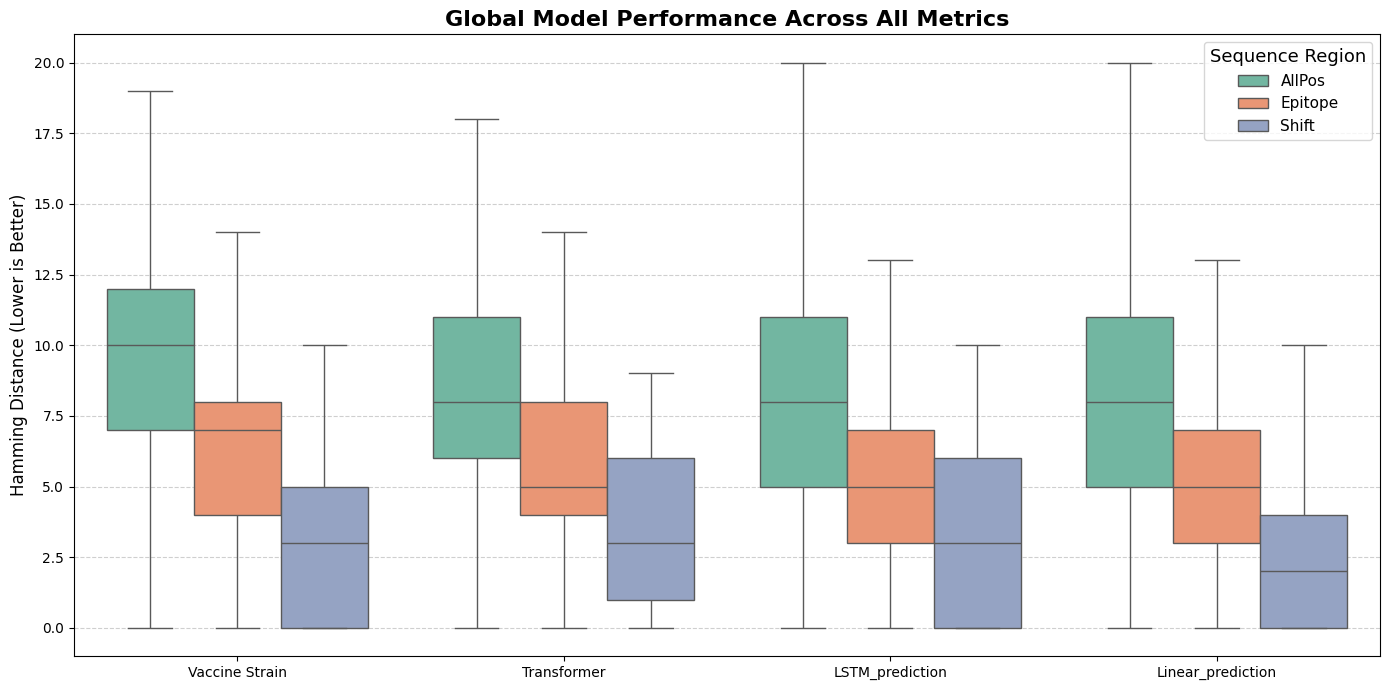

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. 'Melt' the dataframe so all three metrics are in a single column
df_melted = df.melt(
    id_vars=['Test_Seq_ID', 'Season', 'Model'], 
    value_vars=['AllPos_Hamming', 'Epitope_Hamming', 'Shift_Hamming'],
    var_name='Metric', 
    value_name='Hamming_Distance'
)

# Clean up the metric names for the legend
df_melted['Metric'] = df_melted['Metric'].str.replace('_Hamming', '')

# 2. Plotting
plt.figure(figsize=(14, 7))
sns.boxplot(
    data=df_melted, 
    x='Model', 
    y='Hamming_Distance', 
    hue='Metric', 
    showfliers=False,
    palette='Set2'
)

plt.title('Global Model Performance Across All Metrics', fontsize=16, weight='bold')
plt.ylabel('Hamming Distance (Lower is Better)', fontsize=12)
plt.xlabel('')
plt.legend(title='Sequence Region', title_fontsize='13', fontsize='11')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('Combined_Global_MetricsHamming.png', dpi=300)
plt.show()

Generating Small Multiples for AllPos_Accuracy (Unique Sequences)...


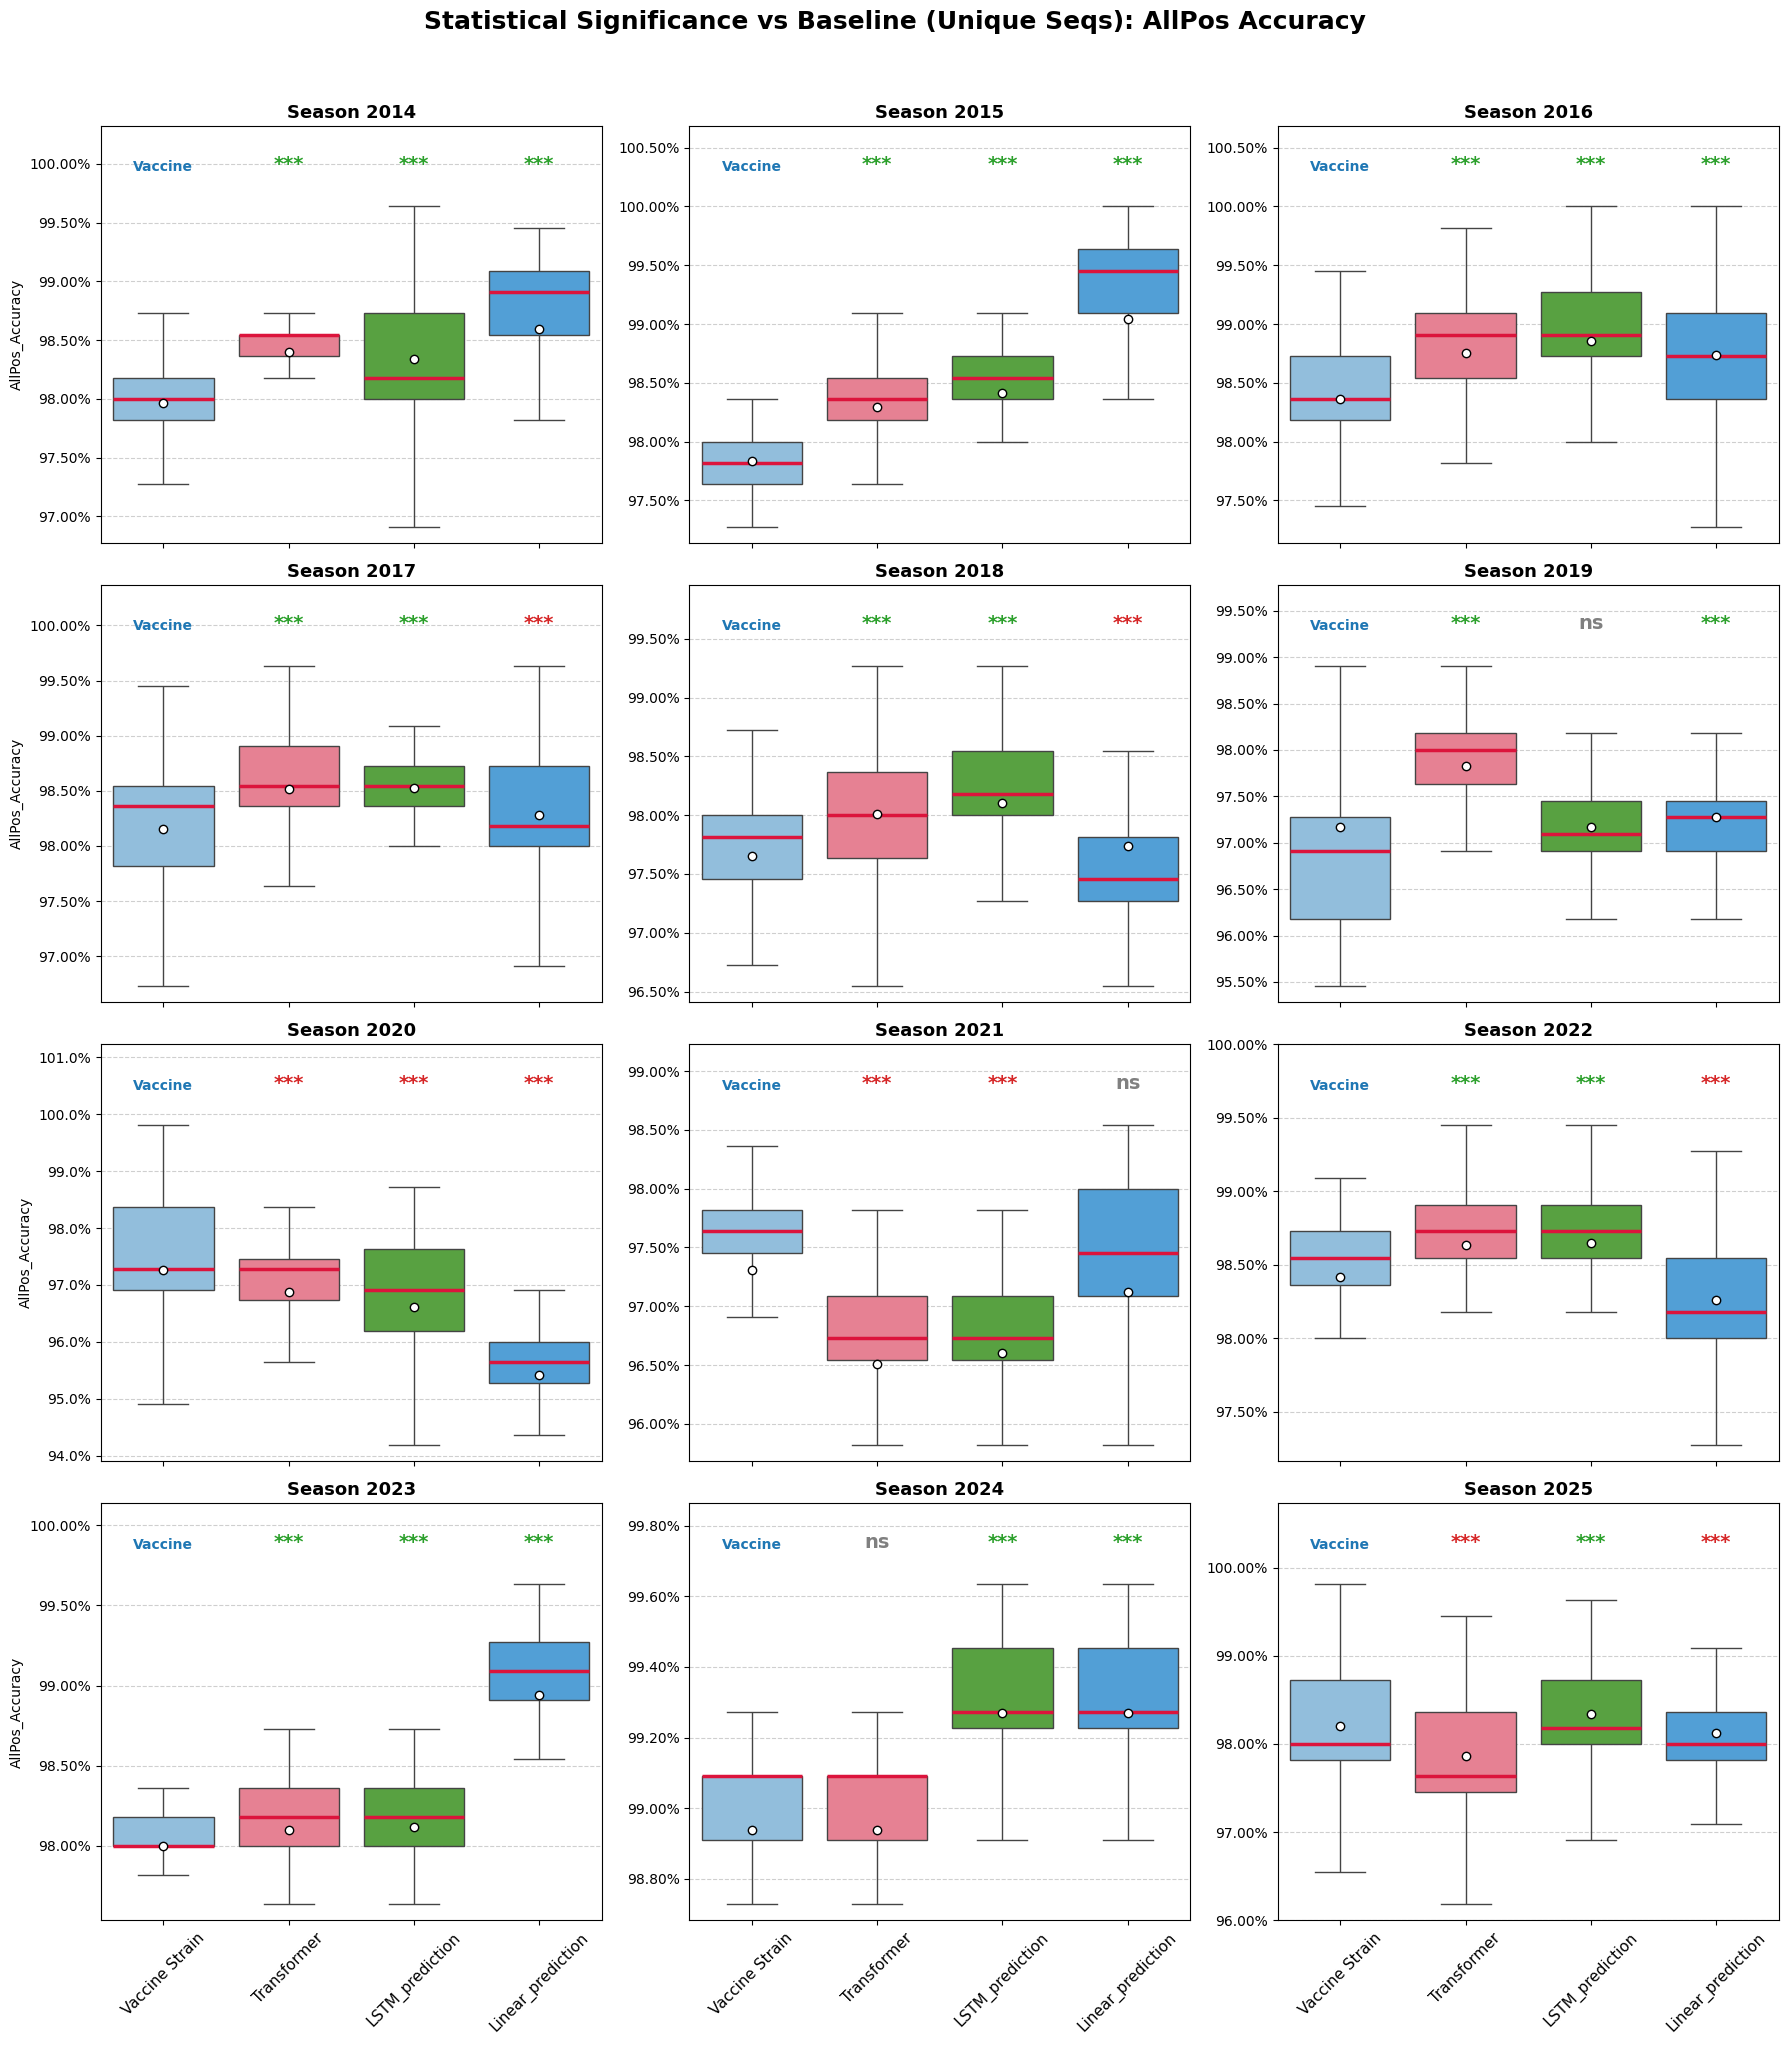

Generating Small Multiples for Shift_Accuracy (Unique Sequences)...


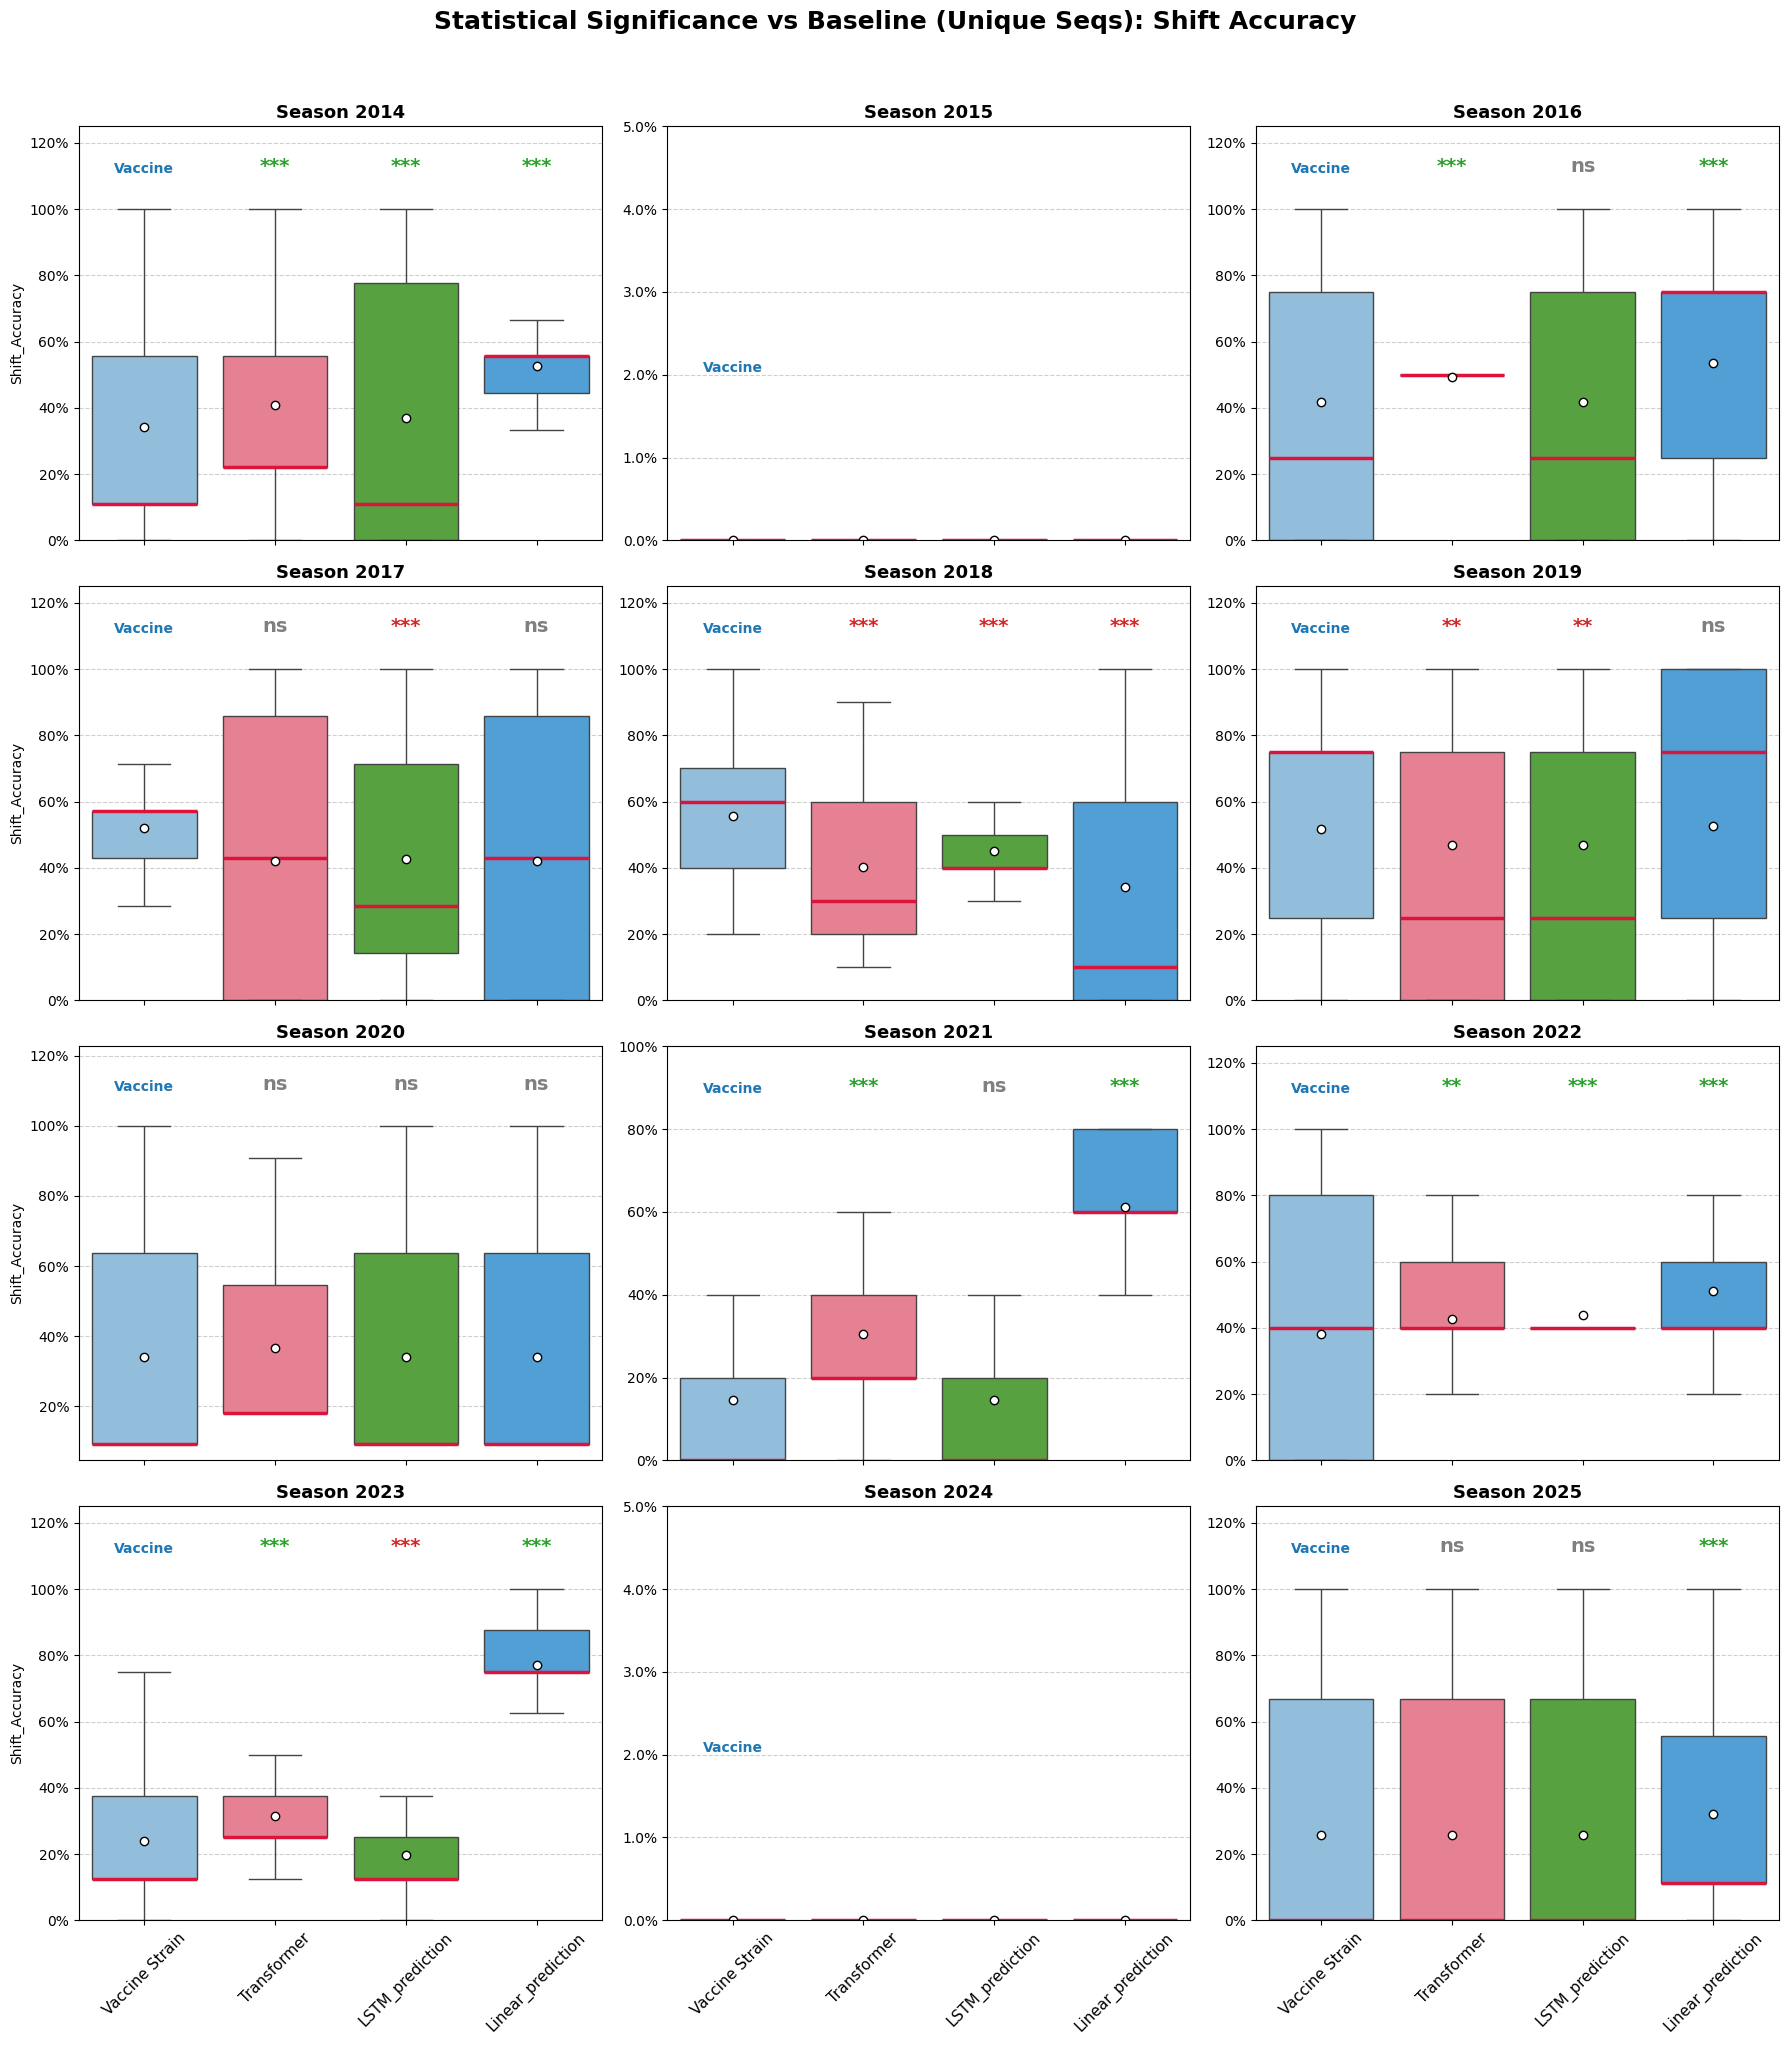

Generating Small Multiples for Epitope_Accuracy (Unique Sequences)...


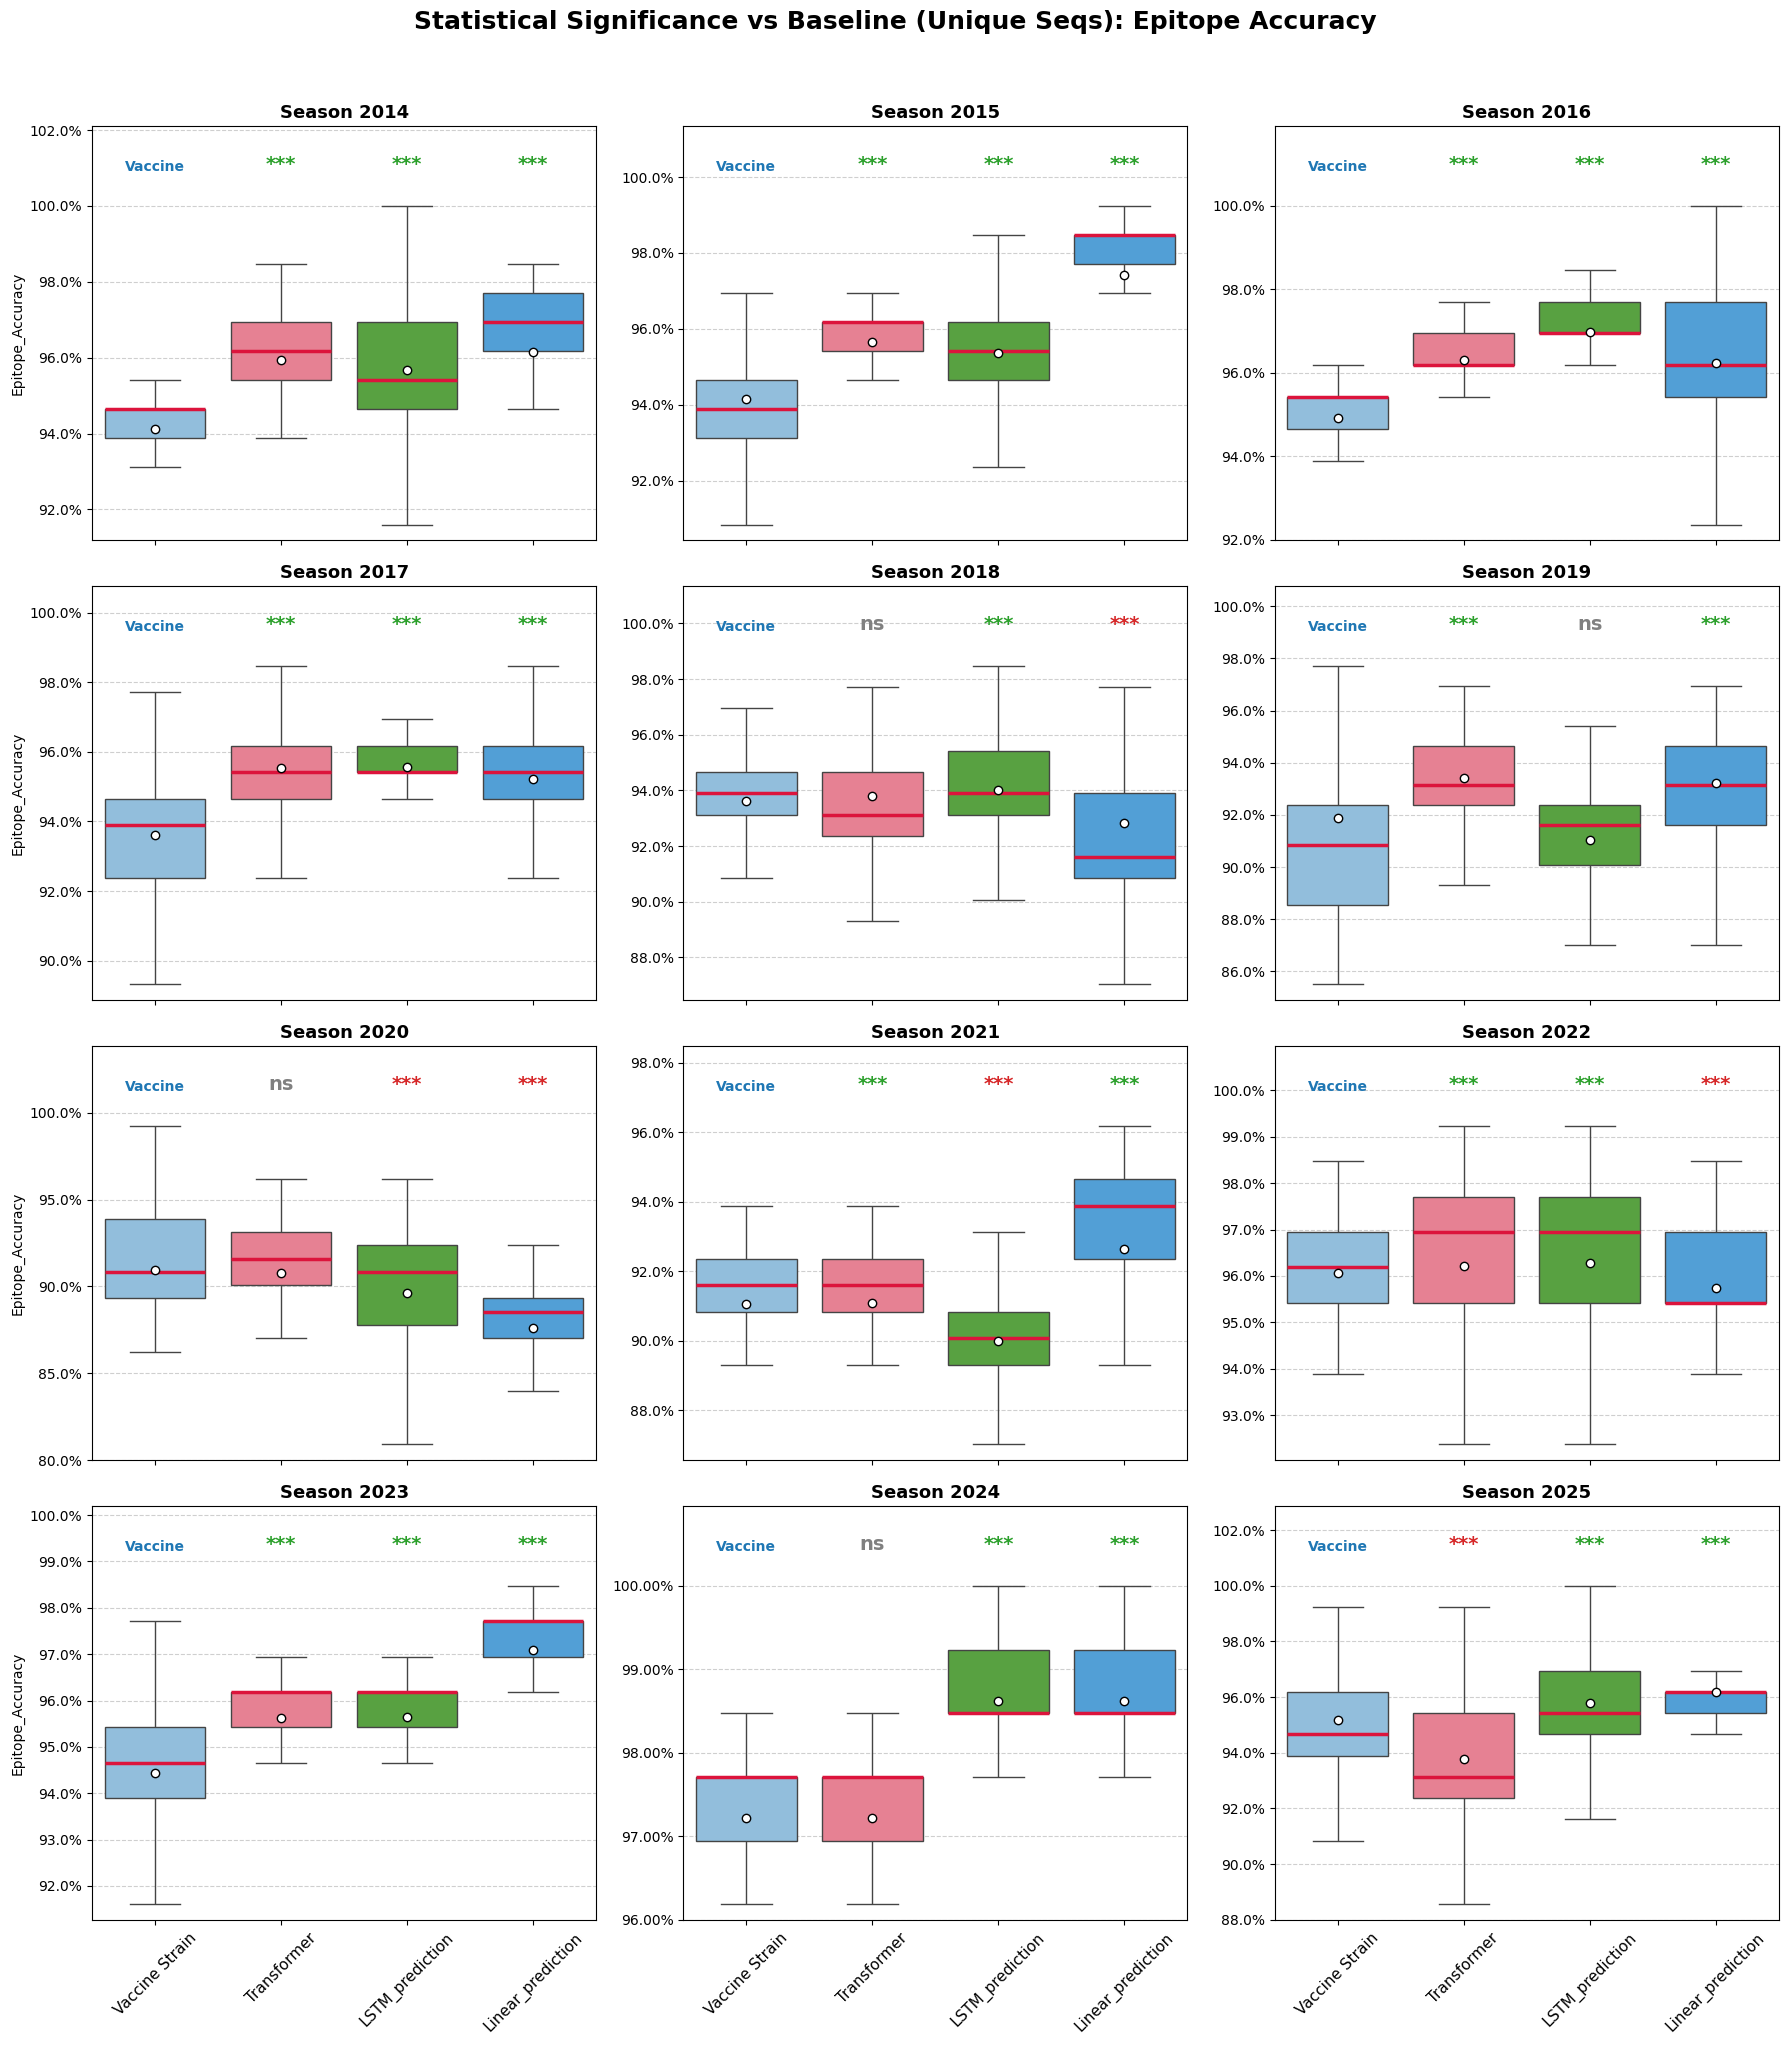


Successfully exported all unique statistical results to Statistical_Significance_Summary_Accuracies.csv!


In [43]:
import matplotlib.ticker as mtick

# ==========================================
# 1. LOAD AND PREP DATA
# ==========================================
df = pd.read_csv('h3n2_clean/h3n2_clean/6b_Raw_Accuracies_Unique.csv')
df = df.rename(columns={'Motif_Accuracy': 'Shift_Accuracy'})
# --- CLEAN NAMES & RANK ---
def fix_model_names(name):
    name_str = str(name).lower()
    if '_vaccine' in name_str or 'vaccine' in name_str: return 'Vaccine Strain'
    if 'hotspot' in name_str: return 'Ensemble_all'
    if 'train' in name_str: return 'Train_consensus'
    if name_str.startswith('ensemble_en'): return 'Ensemble_Entropy'
    if name_str.startswith('representative'): return 'Test_consensus'
    if 'lstm' in name_str: return 'LSTM_prediction'
    if 'linear' in name_str: return 'Linear_prediction'
    if 'transformer_3l' in name_str: return 'Transformer'
    return name

df['Model'] = df['Model'].apply(fix_model_names)
df = df[~df['Model'].str.startswith('Ensemble')]
df = df[~df['Model'].isin(['Transformer_4L', 'Transformer_5L','Train_consensus', 'Test_consensus'])].copy()

baseline_name = 'Vaccine Strain'

def get_asterisks(p_val):
    if pd.isna(p_val): return ""
    if p_val < 0.001: return "***"
    if p_val < 0.01: return "**"
    if p_val < 0.05: return "*"
    return "ns"

# Updated Ranking (Vaccine -> Transformer -> LSTM -> Linear -> Test)
def get_model_rank(name):
    name_str = str(name).lower()
    if 'vaccine' in name_str: return 0
    elif 'transformer' in name_str: return 1
    elif 'lstm' in name_str: return 2
    elif 'linear' in name_str: return 3
    elif 'test' in name_str or 'consensus' in name_str: return 99
    else: return 50

df['Sort_Rank'] = df['Model'].apply(get_model_rank)
df = df.sort_values(by=['Sort_Rank', 'Model']).drop(columns=['Sort_Rank']).reset_index(drop=True)

# Lock in the sorted order so Seaborn doesn't alphabetize it
ordered_models = df['Model'].drop_duplicates().tolist()
df['Model'] = pd.Categorical(df['Model'], categories=ordered_models, ordered=True)

# ==========================================
# 2. PLOTTING FUNCTION FOR SMALL MULTIPLES
# ==========================================
def plot_seasonal_small_multiples(df, metric, p_values_output_list):
    print(f"Generating Small Multiples for {metric} (Unique Sequences)...")
    
    seasons = sorted(df['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 3
    rows = math.ceil(num_seasons / cols)

    unique_sorted_models = df['Model'].dropna().unique()
    
    # Force baseline to the front, keep the rest in custom Sort_Rank order
    order = [baseline_name] + [m for m in unique_sorted_models if m != baseline_name]
    models = [m for m in order if m != baseline_name]
    
    base_colors = sns.color_palette("husl", len(models))
    model_colors = {baseline_name: '#85c1e9'} # Light blue for Baseline
    for idx, m in enumerate(models):
        model_colors[m] = base_colors[idx]
        
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows), sharex=True, sharey=False)
    axes = axes.flatten()
    
    # --- Y-AXIS LIMIT & STAR PLACEMENT ---
    data_max = df[metric].max()
    is_proportion = data_max <= 1.0
    
    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df[df['Season'] == season]

        visible_mins = []
        visible_maxs = []
        
        for m in order:
            group_data = df_season[df_season['Model'] == m][metric].dropna()
            if len(group_data) > 0:
                q1 = group_data.quantile(0.25)
                q3 = group_data.quantile(0.75)
                iqr = q3 - q1
                lower_bound = q1 - 1.5 * iqr
                upper_bound = q3 + 1.5 * iqr
                
                v_min = group_data[group_data >= lower_bound].min()
                v_max = group_data[group_data <= upper_bound].max()
                
                if pd.notna(v_min): visible_mins.append(v_min)
                if pd.notna(v_max): visible_maxs.append(v_max)
                
        local_min = min(visible_mins) if visible_mins else df_season[metric].min()
        local_max = max(visible_maxs) if visible_maxs else df_season[metric].max()
        
        margin = (local_max - local_min) * 0.25
        if margin == 0: 
            margin = 0.05 
            
        star_y_pos = local_max + (margin * 0.4)
        y_plot_top = local_max + margin
        y_plot_bottom = max(0.0, local_min - (margin * 0.2))
        
        # --- BOXPLOT STYLING UPDATES ---
        sns.boxplot(
            data=df_season, x='Model', y=metric, order=order, 
            hue='Model', hue_order=order, dodge=False, legend=False,
            ax=ax, palette=model_colors, showfliers=False,
            showmeans=True, 
            meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": "6"},
            medianprops={"color": "crimson", "linewidth": 2.5} 
        )
        
        df_pivot = df_season.pivot_table(index='Test_Seq_ID', columns='Model', values=metric, aggfunc='mean', observed=False)
        
        if baseline_name in df_pivot.columns:
            baseline_scores = df_pivot[baseline_name]
            
            for j, model in enumerate(order):
                if model == baseline_name:
                    ax.text(j, star_y_pos, 'Vaccine', ha='center', va='bottom', fontsize=10, weight='bold', color='tab:blue')
                    continue
                    
                if model in df_pivot.columns:
                    model_scores = df_pivot[model]
                    
                    valid_mask = ~baseline_scores.isna() & ~model_scores.isna()
                    b_valid = baseline_scores[valid_mask]
                    m_valid = model_scores[valid_mask]
                    
                    # 1. Missing Data Check (0 shifted positions)
                    if len(b_valid) == 0 or len(m_valid) == 0 or ((b_valid == 0).all() and (m_valid == 0).all()):
                        p = pd.NA
                        p_adj = pd.NA
                        stars = '' # Blank on plot
                        m_med = pd.NA
                        b_med = pd.NA
                        color = 'grey'
                        outcome = 'NA'
                        
                    # 2. Valid Data Comparison
                    else:
                        if not b_valid.equals(m_valid):
                            stat, p = wilcoxon(b_valid, m_valid, zero_method='wilcox')
                            p_adj = min(p * len(models), 1.0)
                            stars = get_asterisks(p_adj)
                        else:
                            p = 1.0
                            p_adj = 1.0
                            stars = 'ns'
                            
                        m_med = m_valid.median()
                        b_med = b_valid.median()
                        m_mean = m_valid.mean()
                        b_mean = b_valid.mean()
                        
                        # --- ACCURACY LOGIC (HIGHER IS BETTER) ---
                        if stars != 'ns':
                            if m_med > b_med:
                                color = 'tab:green'
                                outcome = 'Win'
                            elif m_med < b_med:
                                color = 'tab:red'
                                outcome = 'Loss'
                            else: 
                                # Medians identical, tiebreaker with mean
                                if m_mean > b_mean:
                                    color = 'tab:green'
                                    outcome = 'Win (Mean Tiebreaker)'
                                elif m_mean < b_mean:
                                    color = 'tab:red'
                                    outcome = 'Loss (Mean Tiebreaker)'
                                else:
                                    color = 'grey'
                                    outcome = 'Tie'
                        else:
                            color = 'grey'
                            outcome = 'Tie'
                            
                    # Plot the result
                    font_size = 14
                    ax.text(j, star_y_pos, stars, ha='center', va='bottom', fontsize=font_size, weight='bold', color=color)
                    
                    # Append Stats
                    p_values_output_list.append({
                        'Metric': metric,
                        'Season': season,
                        'Model': model,
                        'Baseline_Median': b_med,
                        'Model_Median': m_med,
                        'P_Value_Raw': p,
                        'P_Value_Bonferroni': p_adj,
                        'Significance_Stars': 'NA' if stars == '' else stars,
                        'Outcome (vs Baseline)': outcome
                    })
        else:
            ax.text(0.5, 0.9, 'No Baseline Available', ha='center', va='center', 
                    transform=ax.transAxes, fontsize=12, color='tab:red', alpha=0.5)

        ax.set_title(f"Season {season}", fontsize=13, weight='bold')
        ax.set_xlabel('')
        ax.set_ylabel(f'{metric}' if i % cols == 0 else '')
        
        ax.set_ylim(bottom=y_plot_bottom, top=y_plot_top)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
        ax.yaxis.grid(True, linestyle='--', alpha=0.6)
        ax.tick_params(axis='x', rotation=45, labelsize=11)

    for k in range(i + 1, len(axes)):
        fig.delaxes(axes[k])
        
    plt.suptitle(f'Statistical Significance vs Baseline (Unique Seqs): {metric.replace("_", " ")}', 
                 fontsize=18, weight='bold', y=1.02)
    plt.tight_layout()
    
    filename = f"SmallMultiples_Stats_Unique_{metric}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

# ==========================================
# 3. EXECUTION BLOCK
# ==========================================
# Updated to match the columns shown in your screenshot
metrics_to_plot = ['AllPos_Accuracy', 'Shift_Accuracy', 'Epitope_Accuracy']
all_stats_records = []  

for metric in metrics_to_plot:
    if metric in df.columns:
        plot_seasonal_small_multiples(df, metric, all_stats_records)
    else:
        print(f"Skipping {metric} - Column not found in CSV.")

# Create a DataFrame from the collected stats and export to CSV
df_stats = pd.DataFrame(all_stats_records)

# Save the final file
stats_filename = "Statistical_Significance_Summary_Accuracies.csv"
if not df_stats.empty:
    df_stats.to_csv(stats_filename, index=False)
    print(f"\nSuccessfully exported all unique statistical results to {stats_filename}!")
else:
    print("\nNo statistics were generated. Check if 'Season' and your metrics exist in the dataframe.")